# Task 1 – Data Understanding and Preparation



## Setup

### Imports and paths


In [23]:
from pathlib import Path
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow as pa
import pyarrow.csv as pv
import pyarrow.parquet as pq

ROOT = Path.cwd()
while not (ROOT / "dataset").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA_DIR = ROOT / "dataset"
CSV_PATH = DATA_DIR / "data.csv"  
PARQUET_PATH = DATA_DIR / "data.parquet"  # parquet file path
FIG_DIR = ROOT / "report" / "images" / "task1"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Display and plotting
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
CLASS_COLORS = {"IO": "#eb6834", "control": "#2a78d6"}
LABELS = {"False": "IO", "True": "control"}


def save_fig(name):
    """saving figures to use in the latex report."""
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")


print("Project root:", ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__, "| pyarrow", pa.__version__)

Project root: c:\Users\sheha\Desktop\dm-team\Data-Mining-project-2026
pandas 3.1.0 | numpy 2.5.4 | pyarrow 26.0.0


### Parquet

#### Converting the CSV to Parquet

In [24]:
if PARQUET_PATH.exists():
    print("Parquet file already exists, skipping conversion.")
else:
    start = time.time()
    column_names = pd.read_csv(CSV_PATH, nrows=0).columns.tolist()
    convert_options = pv.ConvertOptions(
        column_types={c: pa.string() for c in column_names},
        strings_can_be_null=True,   # empty fields become null
    )
    parse_options = pv.ParseOptions(newlines_in_values=True)
    read_options = pv.ReadOptions(block_size=64 << 20) 

    reader = pv.open_csv(CSV_PATH, read_options=read_options,
                         parse_options=parse_options, convert_options=convert_options)
    writer = None
    n_rows = 0
    for batch in reader:
        if writer is None:
            writer = pq.ParquetWriter(PARQUET_PATH, batch.schema, compression="zstd")
        writer.write_batch(batch)
        n_rows += batch.num_rows
    writer.close()

    print(f"Converted {n_rows:,} rows in {time.time() - start:.0f} s")

Parquet file already exists, skipping conversion.


**Checking the conversion.**

In [25]:
parquet_file = pq.ParquetFile(PARQUET_PATH)
print(f"Rows:    {parquet_file.metadata.num_rows:,}")
print(f"Columns: {parquet_file.metadata.num_columns}")
print("Names:  ", parquet_file.schema_arrow.names)
print()
print(f"CSV size:     {CSV_PATH.stat().st_size / 1e9:.2f} GB")
print(f"Parquet size: {PARQUET_PATH.stat().st_size / 1e9:.2f} GB")

Rows:    8,714,356
Columns: 20
Names:   ['ioCountry', 'postid', 'post_text', 'application_name', 'post_language', 'in_reply_to_postid', 'in_reply_to_accountid', 'post_time', 'accountid', 'account_profile_description', 'follower_count', 'following_count', 'account_creation_date', 'is_repost', 'reposted_accountid', 'reposted_postid', 'hashtags', 'urls', 'account_mentions', 'is_control']

CSV size:     5.03 GB
Parquet size: 1.18 GB


#### Helper functions for loading data

if we want to load all 20 columns at once would be difficult for ram, so we want to use 2 helper functions that will use all rows but only the columns it needs.

| Helper | When to use it | Memory |
|---|---|---|
| `load(columns)` | almost always | only the requested columns, all rows |
| `iter_chunks(columns)` | heavy text columns (`post_text`, profile descriptions, hashtag/URL/mention lists) | one chunk of rows at a time |


In [26]:
def load(columns):
    return pd.read_parquet(PARQUET_PATH, columns=columns)


def iter_chunks(columns, batch_size=500_000):
    parquet_file = pq.ParquetFile(PARQUET_PATH)
    for batch in parquet_file.iter_batches(batch_size=batch_size, columns=columns):
        yield batch.to_pandas()

#### Loading time


In [27]:
start = time.time()
df = load(["accountid", "ioCountry"])
print(f"2 columns: {time.time() - start:.1f} s, {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

start = time.time()
n_rows = sum(len(chunk) for chunk in iter_chunks(["accountid", "post_text"]))
print(f"post_text in chunks: {n_rows:,} rows in {time.time() - start:.1f} s")
del df

2 columns: 0.3 s, 0.56 GB
post_text in chunks: 8,714,356 rows in 2.8 s


### Pandas

#### Loading the whole CSV

Reading the full CSV into a normal pandas DataFrame, all columns as string.

In [28]:
start = time.time()
df = pd.read_csv(CSV_PATH, dtype=str)
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns in {time.time() - start:.0f} s")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e9:.1f} GB")
del df

Loaded 8,714,356 rows x 20 columns in 42 s
Memory: 6.2 GB


#### Helper functions for loading the CSV


In [29]:
def load_csv(columns):
    return pd.read_csv(CSV_PATH, usecols=columns, dtype=str)


def iter_csv_chunks(columns, chunksize=500_000):
    yield from pd.read_csv(CSV_PATH, usecols=columns, dtype=str, chunksize=chunksize)

**Loading times.**

In [30]:
start = time.time()
df = load_csv(["accountid", "ioCountry"])
print(f"2 columns: {time.time() - start:.1f} s, {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

start = time.time()
n_rows = sum(len(chunk) for chunk in iter_csv_chunks(["accountid", "post_text"]))
print(f"post_text in chunks: {n_rows:,} rows in {time.time() - start:.1f} s")
del df

2 columns: 6.3 s, 0.56 GB
post_text in chunks: 8,714,356 rows in 13.9 s


## Correctness Check

### Loading the entire dataset

In [31]:
df = load(None)
print("Full dataset loaded")

Full dataset loaded


### Dataset dimensions and specification coverage

Check the columns  and report both missing columns and unexpected columns.

In [32]:
expected_columns = [
    "ioCountry", "postid", "post_text", "application_name", "post_language",
    "in_reply_to_postid", "in_reply_to_accountid", "post_time", "accountid",
    "account_profile_description", "follower_count", "following_count",
    "account_creation_date", "is_repost", "reposted_accountid", "reposted_postid",
    "hashtags", "urls", "account_mentions", "is_control",
]

n_rows, n_columns = df.shape
missing_columns = [name for name in expected_columns if name not in df.columns]
unexpected_columns = [name for name in df.columns if name not in expected_columns]
all_present = not missing_columns

print(f"Rows: {n_rows:,}")
print(f"Columns: {n_columns:,}")
print(f"All 20 specified variables present: {all_present}")
print(f"Missing specified columns: {missing_columns}")
print(f"Unexpected columns: {unexpected_columns}")
print(f"Column order matches the brief: {df.columns.tolist() == expected_columns}")

display(pd.DataFrame({
    "Specified variable": expected_columns,
    "Present": [name in df.columns for name in expected_columns],
}))

Rows: 8,714,356
Columns: 20
All 20 specified variables present: True
Missing specified columns: []
Unexpected columns: []
Column order matches the brief: True


,Specified variable,Present
0,ioCountry,True
1,postid,True
2,post_text,True
3,application_name,True
4,post_language,True
5,in_reply_to_postid,True
6,in_reply_to_accountid,True
7,post_time,True
8,accountid,True
9,account_profile_description,True


### A few complete records

The first three records, transposed to show every column.

In [33]:
display(df.head(3).T)

,0,1,2
ioCountry,ecuador,ecuador,ecuador
postid,0bafe020a260495bee38b98fde83668d924454019b,608fba51f2460c7f1ca527dfc48de2bc858d4ad201,514b2c38b26e240cac85382be74ed7d61a02468ac1
post_text,Vamos a cambiar la forma de hacer comunicación...,"Damos servicio de manejo de prensa, elaboració...",@db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302 Bu...
application_name,2727201c363b6fc4afe259ba4094ae0c49cb4df224,2727201c363b6fc4afe259ba4094ae0c49cb4df224,2727201c363b6fc4afe259ba4094ae0c49cb4df224
post_language,NaN,NaN,NaN
in_reply_to_postid,NaN,NaN,f29b32f8dbaa1e0f00152decbcc2bd93dddc740464
in_reply_to_accountid,NaN,NaN,db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302
post_time,2010-03-13 02:52:00,2010-03-13 03:08:00,2010-03-13 15:26:00
accountid,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,2c6c0ef5f445760177b016e33b36809bde3c7ac241
account_profile_description,"#Periodismo, #RelacionesPúblicas, #Comunicac...","#Periodismo, #RelacionesPúblicas, #Comunicac...",NaN


## Data semantics
Attribute types from the slide (nominal, binary, ordinal, interval, ratio).

### Variable-by-variable structural inventory 
- **Note:** when we load from csv file and not parquit file the is_repost column is recognized as a bool. 
- **Pandas dtype:** the dtype inferred at import, without conversion.

In [34]:
# All counts cover every imported row. No changes are assigned back to df.
inventory = pd.DataFrame({
    "Variable": df.columns,
    "Pandas dtype": [str(df[name].dtype) for name in df.columns],
})

display(inventory)

,Variable,Pandas dtype
0,ioCountry,str
1,postid,str
2,post_text,str
3,application_name,str
4,post_language,str
5,in_reply_to_postid,str
6,in_reply_to_accountid,str
7,post_time,str
8,accountid,str
9,account_profile_description,str


### Observations from previous sections

In [35]:
print(f"- Number of rows (posts): {n_rows:,}")
print(f"- Number of columns: {n_columns:,}")
print(f"- All 20 specified variables present: {'Yes' if all_present else 'No'}")
print("- Pandas dtypes: see the 'Pandas dtype' inventory column.")

- Number of rows (posts): 8,714,356
- Number of columns: 20
- All 20 specified variables present: Yes
- Pandas dtypes: see the 'Pandas dtype' inventory column.


### Overview

In [36]:
df = load(["ioCountry", "accountid", "is_control", "post_time"])
post_time = pd.to_datetime(df["post_time"])

print(f"Posts:     {len(df):,}")
print(f"Accounts:  {df['accountid'].nunique():,}")
print(f"Campaigns: {df['ioCountry'].nunique()} {sorted(df['ioCountry'].unique())}")
print(f"From {post_time.min()} to {post_time.max()}")

Posts:     8,714,356
Accounts:  85,156
Campaigns: 5 ['ecuador', 'iran_1', 'iran_4', 'russia_1', 'uae']
From 2008-04-30 10:35:00 to 2019-07-30 23:59:56


In [37]:
overview = df.groupby(["ioCountry", "is_control"]).agg(
    posts=("accountid", "size"),
    accounts=("accountid", "nunique"),
).unstack()
del df, post_time
overview

posts                      accounts                   
is_control    False     True is_control?    False   True is_control?
ioCountry                                                           
ecuador      700274   770338         207      787  21138         174
iran_1      1122977   199873         173      660   5015          81
iran_4       254797   306822          64     2519   7612          56
russia_1    1826432  1823841         455     3293  31299         407
uae         1325597   382293         213     3658  10545         195

**One example post** (first three rows, shown vertically).

### Groups of variables



| Group | Columns |
| --- | --- |
| Post | `postid`, `post_text`, `post_time`, `post_language`, `application_name` |
| Interaction | `in_reply_to_postid`, `in_reply_to_accountid`, `is_repost`, `reposted_accountid`, `reposted_postid`, `hashtags`, `urls`, `account_mentions` |
| Account | `accountid`, `account_profile_description`, `follower_count`, `following_count`, `account_creation_date` |
| Campaign and label | `ioCountry`, `is_control` |

### Data dictionary

| Column | Meaning | Semantic type | Discrete / continuous | Actual dtype |
| --- | --- | --- | --- | --- |
| `ioCountry` | campaign the post was collected for | nominal | discrete | <code>str</code> |
| `postid` | anonymised id of the post | nominal (identifier) | discrete | <code>str</code> |
| `post_text` | text of the post | document data (nominal in principle) | – | <code>str</code> |
| `application_name` | app used to publish (hashed) | nominal | discrete | <code>str</code> |
| `post_language` | language code of the post | nominal | discrete | <code>str</code> |
| `in_reply_to_postid` | the post being replied too | nominal (identifier) | discrete | <code>str</code> |
| `in_reply_to_accountid` | the author of that post | nominal (identifier) | discrete | <code>str</code> |
| `post_time` | date and time of publication | interval | continuous | <code>str</code> |
| `accountid` | anonymised id of the author | nominal (identifier) | discrete | <code>str</code> |
| `account_profile_description` | bio of the account | document data (nominal in principle) | – | <code>str</code> |
| `follower_count` | followers of the account | ratio | discrete | <code>str</code> |
| `following_count` | accounts it follows | ratio | discrete | <code>str</code> |
| `account_creation_date` | date the account was created | interval | continuous | <code>str</code> |
| `is_repost` | the post is a repost | asymmetric binary | discrete | <code>str</code> |
| `reposted_accountid` | author of the reposted post | nominal (identifier) | discrete | <code>str</code> |
| `reposted_postid` | the reposted post | nominal (identifier) | discrete | <code>str</code> |
| `hashtags` | hashtags in the post | set of nominal items (transaction data) | discrete | <code>str</code> |
| `urls` | links in the post (hashed) | set of nominal items (transaction data) | discrete | <code>str</code> |
| `account_mentions` | accounts mentioned in the post | set of nominal items (transaction data) | discrete | <code>str</code> |
| `is_control` | class label: True = control, False = IO | asymmetric binary | discrete | <code>str</code> |


### Cardinality and uniqueness inspection

The table below shows the number of distinct non-missing values (**cardinality**) and compares it with the number of non-missing entries:

- **Unique / non-missing (%)** is the distinct count divided by the non-missing count. A value of 100% means every observed entry is different; lower values mean more repetition.
- **Occurrences beyond first** counts additional occurrences after the first appearance of each value, excluding missing entries.
- **Unique among observed** marks columns with no repeated non-missing values. **Complete unique column** also requires that no entries are missing, making the column a possible record key.

Values are compared as stored. For `hashtags`, `urls` and `account_mentions`, the counts refer to entire stored strings, not individual items within them.


In [38]:
df = load(None)

cardinality = pd.DataFrame()

cardinality["Variable"] = df.columns
cardinality["Unique non-missing"] = [df[name].nunique(dropna=True) for name in df.columns]
cardinality["Missing"] = [int(df[name].isna().sum()) for name in df.columns]
cardinality["Non-missing"] = len(df) - cardinality["Missing"]
cardinality["Unique / non-missing (%)"] = (
    100 * cardinality["Unique non-missing"]
    / cardinality["Non-missing"].where(cardinality["Non-missing"].gt(0))
)
cardinality["Occurrences beyond first"] = (
    cardinality["Non-missing"] - cardinality["Unique non-missing"]
)
cardinality["Unique among observed"] = (
    cardinality["Non-missing"].gt(0)
    & cardinality["Unique non-missing"].eq(cardinality["Non-missing"])
)
cardinality["Complete unique column"] = (
    cardinality["Unique among observed"] & cardinality["Missing"].eq(0)
)
cardinality = cardinality[[
    "Variable", "Non-missing", "Missing", "Unique non-missing",
    "Unique / non-missing (%)", "Occurrences beyond first",
    "Unique among observed", "Complete unique column",
]]

cardinality["example"] = [df[name].dropna().iloc[0][:60] if cardinality.loc[i, "Non-missing"] > 0 else None for i, name in enumerate(df.columns)]

display(cardinality)

,Variable,Non-missing,Missing,Unique non-missing,Unique / non-missing (%),Occurrences beyond first,Unique among observed,Complete unique column,example
0,ioCountry,8714356,0,5,0.000,8714351,False,False,ecuador
1,postid,8714356,0,8691447,99.737,22909,False,False,0bafe020a260495bee38b98fde83668d924454019b
2,post_text,8714353,3,7100326,81.479,1614027,False,False,Vamos a cambiar la forma de hacer comunicación...
3,application_name,8714356,0,3728,0.043,8710628,False,False,2727201c363b6fc4afe259ba4094ae0c49cb4df224
4,post_language,8610613,103743,70,0.001,8610543,False,False,es
5,in_reply_to_postid,886242,7828114,794607,89.660,91635,False,False,f29b32f8dbaa1e0f00152decbcc2bd93dddc740464
6,in_reply_to_accountid,875087,7839269,374094,42.749,500993,False,False,db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302
7,post_time,8714356,0,4674914,53.646,4039442,False,False,2010-03-13 02:52:00
8,accountid,8714356,0,85156,0.977,8629200,False,False,22de67d991b31493165b9270f7d8b5b4ce712d5fc8
9,account_profile_description,7044437,1669919,64100,0.910,6980337,False,False,"#Periodismo, #RelacionesPúblicas, #Comunicac..."


### Post and account identifiers: repeated values versus extra occurrences

For `postid` and `accountid`, distinguish:

- identifiers appearing exactly once;
- distinct identifiers appearing more than once;
- all records carrying a repeated identifier;
- occurrences beyond the first for each identifier;
- the largest number of records sharing one identifier.


In [39]:

identifier_counts = {}
identifier_rows = []
for name in ["postid", "accountid"]:
    counts = df[name].value_counts(dropna=True)
    identifier_counts[name] = counts
    repeated = counts.gt(1)
    identifier_rows.append({
        "Identifier": name,
        "Missing": int(df[name].isna().sum()),
        "Distinct observed IDs": len(counts),
        "IDs occurring once": int(counts.eq(1).sum()),
        "IDs occurring more than once": int(repeated.sum()),
        "Records with repeated IDs": int(counts[repeated].sum()),
        "Occurrences beyond first": int((counts - 1).sum()),
        "Maximum records per ID": int(counts.max()) if len(counts) else 0,
    })
identifier_summary = pd.DataFrame(identifier_rows)
with pd.option_context("display.max_columns", None):
    display(identifier_summary)

,Identifier,Missing,Distinct observed IDs,IDs occurring once,IDs occurring more than once,Records with repeated IDs,Occurrences beyond first,Maximum records per ID
0,postid,0,8691447,8668742,22705,45614,22909,4
1,accountid,0,85156,5950,79206,8708406,8629200,265498


### Which values occur in the smallest domains?

For columns with at most **80 distinct non-missing values**, show every observed value, its count, and its percentage of all records. 80 is only a display limit. String values are shown with quotes so they remain distinguishable from booleans.


In [40]:

inventory = pd.DataFrame({
    "Variable": df.columns,
    "# unique": [df[name].nunique(dropna=True) for name in df.columns],
})

small_domain_columns = inventory.loc[inventory["# unique"].le(80), "Variable"].tolist()
for name in small_domain_columns:
    frequencies = df[name].value_counts(dropna=False)
    domain = pd.DataFrame({
        "Observed value (repr)": [repr(value) for value in frequencies.index],
        "Records": frequencies.to_numpy(),
        "Share of all records (%)": 100 * frequencies.to_numpy() / len(df),
    })
    print(f"{name}: {df[name].dtype}")
    with pd.option_context("display.max_rows", None, "display.float_format", "{:.4f}".format):
        display(domain)

ioCountry: str


,Observed value (repr),Records,Share of all records (%)
0,'russia_1',3650728,41.8933
1,'uae',1708103,19.6010
2,'ecuador',1470819,16.8781
3,'iran_1',1323023,15.1821
4,'iran_4',561683,6.4455


post_language: str


,Observed value (repr),Records,Share of all records (%)
0,'en',2498059,28.6660
1,'ru',1569218,18.0073
2,'ar',1378463,15.8183
3,'es',1360647,15.6139
4,'fr',419225,4.8107
5,'und',373102,4.2815
6,'fa',317265,3.6407
7,'pt',134525,1.5437
8,'tr',131050,1.5038
9,nan,103743,1.1905


is_repost: str


,Observed value (repr),Records,Share of all records (%)
0,'False',5109181,58.6295
1,'True',3605175,41.3705


is_control: str


,Observed value (repr),Records,Share of all records (%)
0,'False',5230077,60.0168
1,'True',3483167,39.9704
2,'is_control?',1112,0.0128


## Data quality

missing values, syntactic and semantic errors, duplicates, inconsistencies and outliers. In this part we only find and count them, the fixes will be done in the cleaning part.

### Missing values

Count nulls with `.isna()` and report possible missing-value markers separately. `Needs review` excludes known non-reposts for repost targets and counts only one-sided gaps in reply targets.


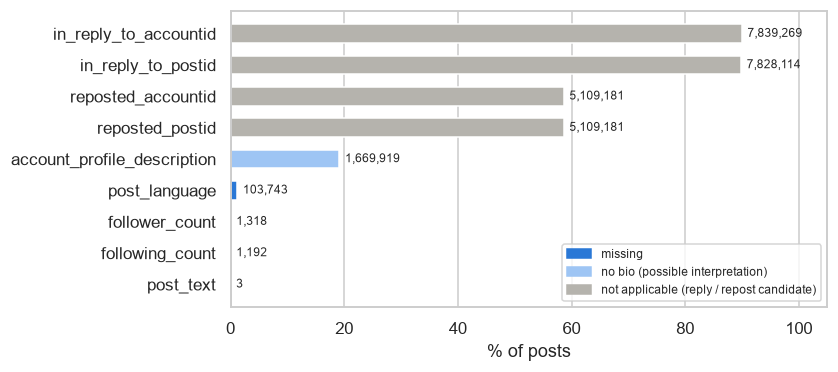

,Missing,pct,kind,Needs review
Variable,,,,
ioCountry,0,0.000,missing,0
postid,0,0.000,missing,0
application_name,0,0.000,missing,0
post_time,0,0.000,missing,0
account_creation_date,0,0.000,missing,0
is_repost,0,0.000,missing,0
accountid,0,0.000,missing,0
hashtags,0,0.000,missing,0
is_control,0,0.000,missing,0


,Variable,stored_value,Rows,counted_as_missing
0,post_text,'Null',1,False
1,post_text,'\u2003\u2003\u2003\u2003\u2003\u2003\u2003\u2...,1,False
2,post_text,'\u2003\n\n\u2003',1,False
3,post_text,'?',12,False
4,post_text,'-',5,False
5,post_language,'und',373102,False
6,account_profile_description,'-',114,False
7,account_profile_description,'?',31,False
8,account_profile_description,'Undefined',10,False
9,account_profile_description,'Unknown',27,False


In [41]:
N_ROWS = len(df)
not_applicable = ["in_reply_to_postid", "in_reply_to_accountid", "reposted_accountid", "reposted_postid"]

# Count only actual nulls as missing; keep text markers in the separate audit.
NA_MARKERS = {"", "na", "n/a", "nan", "null", "none", "<na>"}
HIDDEN_MARKERS = NA_MARKERS | {"unknown", "undefined", "missing", "und", "-", "?"}


summary_rows, marker_rows = [], []
for name in df.columns:
    frequencies = df[name].value_counts(dropna=False, sort=False)
    domain = pd.Series(frequencies.index, dtype="string")
    absent_domain = domain.isna()
    # No length limit: include long whitespace-only strings in the audit too.
    marker_candidates = domain.notna() & domain.str.strip().str.casefold().isin(HIDDEN_MARKERS)
    for position in marker_candidates.index[marker_candidates.fillna(False)]:
        marker_rows.append({
            "Variable": name, "stored_value": repr(domain.iloc[position]),
            "Rows": int(frequencies.iloc[position]),
            "counted_as_missing": bool(absent_domain.iloc[position]),
        })

    missing_count = int(df[name].isna().sum())
    # Review repost targets unless the post is explicitly a non-repost.
    # Review reply targets when only one of the paired targets is absent.
    review_count = missing_count
    if name in {"reposted_postid", "reposted_accountid"}:
        known_non_repost = df["is_repost"].astype("string").str.strip().str.casefold().eq("false").fillna(False)
        review_count = int((df[name].isna() & ~known_non_repost).sum())
    elif name in {"in_reply_to_postid", "in_reply_to_accountid"}:
        paired = "in_reply_to_accountid" if name == "in_reply_to_postid" else "in_reply_to_postid"
        review_count = int((df[name].isna() & ~df[paired].isna()).sum())

    summary_rows.append({"Variable": name, "Missing": missing_count, "Needs review": review_count})
    del frequencies, domain

missing = pd.DataFrame(summary_rows).set_index("Variable")
missing["pct"] = 100 * missing["Missing"] / N_ROWS if N_ROWS else 0.0
missing["kind"] = np.where(missing.index.isin(not_applicable), "not applicable", "missing")
missing.loc[missing.index == "account_profile_description", "kind"] = "no bio"
missing = missing[["Missing", "pct", "kind", "Needs review"]].sort_values("pct")
hidden_marker_audit = pd.DataFrame(marker_rows, columns=["Variable", "stored_value", "Rows", "counted_as_missing"])

# Match the original figure; keep complete fields in the table but omit their zero-length bars.
shown = missing.loc[missing["Missing"] > 0]
fig, ax = plt.subplots(figsize=(7, 3.5))
KIND_COLORS = {"missing": CLASS_COLORS["control"], "no bio": "#9ec5f4", "not applicable": "#b5b3ad"}
colors = shown["kind"].map(KIND_COLORS)
ax.barh(shown.index, shown["pct"], color=colors, height=0.6)
for name, row in shown.iterrows():
    ax.text(row["pct"] + 1, name, f"{row['Missing']:,}", va="center", fontsize=8)
ax.set_xlabel("% of posts")
ax.set_xlim(0, 105)
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in KIND_COLORS.values()]
ax.legend(handles, ["missing", "no bio (possible interpretation)", "not applicable (reply / repost candidate)"], loc="lower right", fontsize=8)
save_fig("missing_values")
plt.show()
display(missing)
display(hidden_marker_audit)


**Findings**

- Nulls occur in profile descriptions (1,669,919), language (103,743), follower counts (1,318), following counts (1,192), and post text (3).
- Missing repost targets match non-reposts. However, 63,468 posts have `in_reply_to_accountid` filled but `in_reply_to_postid` missing; another 74,623 have the reverse pattern. These incomplete reply pairs need checking against the source conventions, but are not confirmed errors. Rows where both reply fields are missing are excluded from `Needs review`, since they may be non-replies.
- Text markers and whitespace are reported separately, including 373,102 `und` language values; they are excluded from null counts.


Compare missing language values between IO and control posts, and count `und` (undetermined language) separately.


In [42]:
lang = load(["post_language", "is_control"])
print(pd.crosstab(lang["post_language"].isna(), lang["is_control"]).rename(index={False: "has language", True: "missing"}))
print(f"\nund: {(lang['post_language'] == 'und').sum():,} posts")
del lang

is_control       False     True  is_control?
post_language                               
has language   5126346  3483167         1100
missing         103731        0           12

und: 373,102 posts


### Errors and inconsistencies

#### Syntactic errors

now we want to see values that don't have the expected format. For each column we write the format a correct value should have and count the values that don't match it (empty values are not counted here).

In [43]:
HEX_ID = r"[0-9a-f]{42}"
LIST = r"\[.*\]"
FORMATS = {
    "ioCountry": r"ecuador|iran_1|iran_4|russia_1|uae",
    "postid": HEX_ID,
    "application_name": HEX_ID,
    "post_language": r"[a-z]{2,3}",
    "in_reply_to_postid": HEX_ID,
    "in_reply_to_accountid": HEX_ID,
    "post_time": r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}",
    "accountid": HEX_ID,
    "follower_count": r"-?\d+",
    "following_count": r"-?\d+",
    "account_creation_date": r"\d{4}-\d{2}-\d{2}",
    "is_repost": r"True|False",
    "reposted_accountid": HEX_ID,
    "reposted_postid": HEX_ID,
    "hashtags": LIST,
    "urls": LIST,
    "account_mentions": LIST,
    "is_control": r"True|False",
}

wrong = {}
for col, pattern in FORMATS.items():
    s = load([col])[col].dropna()
    wrong[col] = (~s.str.fullmatch(pattern, flags=re.S)).sum()
del s
pd.Series(wrong, name="wrong format").to_frame()

,wrong format
ioCountry,0
postid,0
application_name,0
post_language,0
in_reply_to_postid,0
in_reply_to_accountid,0
post_time,0
accountid,0
follower_count,2265
following_count,2160


Only three columns have wrongly formatted values. These are the wrong values:

In [44]:
counts = load(["follower_count", "following_count", "is_control"])
for col in ["follower_count", "following_count", "is_control"]:
    s = counts[col].dropna()
    bad = s[~s.str.fullmatch(FORMATS[col])]
    print(f"{col}: {len(bad):,} wrong values")
    print(bad.value_counts().to_dict(), "\n")

follower_count: 2,265 wrong values
{'error': 281, 'unknown': 268, 'NaN-ish': 258, 'none': 256, 'many': 236, '4O00': 210, '12abc': 202, '1,2,3': 193, '??42': 191, 'ten': 170} 

following_count: 2,160 wrong values
{'NaN-ish': 258, 'unknown': 249, 'many': 244, 'none': 243, 'error': 227, '12abc': 212, 'ten': 200, '??42': 193, '1,2,3': 167, '4O00': 167} 

is_control: 1,112 wrong values
{'is_control?': 1112} 



#### Collection serialization and count reliability

The fields `hashtags`, `urls`, and `account_mentions` contain textual representations of collections. This audit evaluates each distinct stored representation and weights the results by its frequency across the full dataset.

The output reports the number of distinct representations, affected records, and percentage of all records for each status, together with up to three frequent examples per status and a summary of issues requiring investigation. Counts refer to stored elements, including repetitions, rather than unique elements. 


In [45]:
import gc
from typing import NamedTuple


class CollectionInspection(NamedTuple):
    status: str
    count: int | None


# Quoted strings may contain escaped characters. Ellipses inside quotes are data.
_COLLECTION_TOKEN = re.compile(r"'(?:\\.|[^'\\])*'|\"(?:\\.|[^\"\\])*\"|\.{3}|\u2026", flags=re.S)
_COLLECTION_SEPARATOR = re.compile(r"\s*,\s*|\s+")


def inspect_collection(value):
    """Count only fully recognized flat, bracketed collections of quoted strings."""
    if pd.isna(value):
        return CollectionInspection("missing_null", None)
    if not isinstance(value, str):
        return CollectionInspection("unparsed_collection", None)
    stored = value.strip()
    if not stored:
        return CollectionInspection("missing_whitespace", None)
    if not (stored.startswith("[") and stored.endswith("]")):
        return CollectionInspection("unparsed_collection", None)
    body = stored[1:-1].strip()
    if not body:
        return CollectionInspection("empty_collection", 0)

    position, count, elided = 0, 0, False
    while position < len(body):
        token = _COLLECTION_TOKEN.match(body, position)
        if token is None:
            return CollectionInspection("unparsed_collection", None)
        if token.group() in {"...", "\u2026"}:
            elided = True
        else:
            count += 1
        position = token.end()
        if position == len(body):
            break
        separator = _COLLECTION_SEPARATOR.match(body, position)
        if separator is None:
            return CollectionInspection("unparsed_collection", None)
        position = separator.end()

    if elided:
        return CollectionInspection("elided_representation", None)
    return CollectionInspection("parsed_collection", count)


collection_columns = ["hashtags", "urls", "account_mentions"]
collection_counts, collection_rows, collection_example_rows = {}, [], []
collection_issue_rows = []
for name in collection_columns:
    frequencies = df[name].value_counts(dropna=False, sort=False)
    domain = frequencies.rename_axis("stored_value").reset_index(name="rows")
    diagnostics = [inspect_collection(value) for value in domain["stored_value"]]
    domain["status"] = [result.status for result in diagnostics]
    domain["diagnostic_count"] = [np.nan if result.count is None else result.count for result in diagnostics]
    del diagnostics

    lookup = domain.set_index("stored_value")
    row_status = df[name].map(lookup["status"])
    collection_counts[name] = df[name].map(lookup["diagnostic_count"]).astype("float64")
    missing_collection = row_status.isin(["missing_null", "missing_whitespace"])
    collection_counts[name] = collection_counts[name].mask(missing_collection)

    for status, group in domain.groupby("status", sort=True):
        affected_rows = int(group["rows"].sum())
        collection_rows.append({
            "column": name, "status": status, "distinct_stored_values": len(group),
            "rows": affected_rows, "percentage": 100 * affected_rows / N_ROWS,
        })
        for example in group.sort_values("rows", ascending=False).head(3).itertuples(index=False):
            collection_example_rows.append({
                "column": name, "status": status, "rows": int(example.rows),
                "stored_value": example.stored_value, "diagnostic_count": example.diagnostic_count,
            })

    unknown_nonmissing = collection_counts[name].isna() & ~missing_collection
    elided_rows = row_status.eq("elided_representation")
    # Local issue summary: the notebook has no shared add_issue() registry.
    collection_issue_rows.extend([
        {"issue": f"{name}_unparsed_collection",
         "rows": int((unknown_nonmissing & ~elided_rows).sum()),
         "interpretation": "Serialization requires investigation."},
        {"issue": f"{name}_elided_collection",
         "rows": int(elided_rows.sum()),
         "interpretation": "An unquoted ellipsis may indicate omitted elements."},
    ])
    print(f"{name}: assessed {len(frequencies):,} distinct values covering {int(frequencies.sum()):,} rows.")
    del frequencies, domain, lookup, row_status, missing_collection, unknown_nonmissing, elided_rows, group
    gc.collect()

collection_quality = pd.DataFrame(collection_rows)
collection_examples = pd.DataFrame(collection_example_rows)
collection_issues = pd.DataFrame(collection_issue_rows)
display(collection_quality)
with pd.option_context("display.max_colwidth", 160):
    display(collection_examples)
    display(collection_issues)


hashtags: assessed 991,195 distinct values covering 8,714,356 rows.
urls: assessed 3,719,646 distinct values covering 8,714,356 rows.
account_mentions: assessed 1,423,441 distinct values covering 8,714,356 rows.


,column,status,distinct_stored_values,rows,percentage
0,hashtags,empty_collection,1,4743185,54.430
1,hashtags,parsed_collection,991194,3971171,45.570
2,urls,empty_collection,1,3621563,41.559
3,urls,parsed_collection,3719645,5092793,58.441
4,account_mentions,empty_collection,1,3681003,42.241
5,account_mentions,parsed_collection,1423440,5033353,57.759


,column,status,rows,stored_value,diagnostic_count
0,hashtags,empty_collection,4743185,[],0
1,hashtags,parsed_collection,82511,['новости'],1
2,hashtags,parsed_collection,37922,['news'],1
3,hashtags,parsed_collection,31285,['MTVHottest'],1
4,urls,empty_collection,3621563,[],0
5,urls,parsed_collection,10365,['https://59b589ac9a11031761244285b4f3662384e74b4f39'],1
6,urls,parsed_collection,10062,['https://305ccb8bc2c322637279932921ba73f0c986367629'],1
7,urls,parsed_collection,6252,['https://91520cc1751fbe5e09ea811bb94ba75eeea0471435'],1
8,account_mentions,empty_collection,3681003,[],0
9,account_mentions,parsed_collection,117081,['5582e3050b782a395d52df2e37ad8187a614640428'],1


,issue,rows,interpretation
0,hashtags_unparsed_collection,0,Serialization requires investigation.
1,hashtags_elided_collection,0,An unquoted ellipsis may indicate omitted elements.
2,urls_unparsed_collection,0,Serialization requires investigation.
3,urls_elided_collection,0,An unquoted ellipsis may indicate omitted elements.
4,account_mentions_unparsed_collection,0,Serialization requires investigation.
5,account_mentions_elided_collection,0,An unquoted ellipsis may indicate omitted elements.


**Findings**

Evaluating all **8,714,356 records** for each of the three collection fields. percentages in the results below use the full dataset as the denominator.

| Field | Distinct stored representations | Empty collections, records (%) | Non-empty parsed collections, records (%) |
| --- | ---: | ---: | ---: |
| `hashtags` | 991,195 | 4,743,185 (54.430%) | 3,971,171 (45.570%) |
| `urls` | 3,719,646 | 3,621,563 (41.559%) | 5,092,793 (58.441%) |
| `account_mentions` | 1,423,441 | 3,681,003 (42.241%) | 5,033,353 (57.759%) |

- Every observed representation was recognized as either an empty collection or a non-empty collection of quoted strings. No null or whitespace-only values were observed in these fields.
- No unparsed collections or representations containing an unquoted ellipsis were detected. Consequently, both issue categories contain zero affected records for all three fields, and an element count is available for every record.
- Empty collections are represented by `[]` and receive a count of zero. They indicate the absence of stored elements and are distinguished from unavailable counts.


#### Semantic errors

In [ ]:
for col in ["follower_count", "following_count"]:
    n = pd.to_numeric(counts[col], errors="coerce")
    print(f"{col}: negative {(n < 0).sum():,}, above 1 billion {(n > 1e9).sum():,}")
    print(f"   largest value below 1 billion: {n[n < 1e9].max():,.0f}, smallest above: {n[n > 1e9].min():,.0f}")
del counts, n

follower_count: negative 977, above 1 billion 493
   largest value below 1 billion: 19,912,528, smallest above: 10,080,725,079
following_count: negative 1,029, above 1 billion 518
   largest value below 1 billion: 2,301,841, smallest above: 10,150,822,424


as our understanding we can say that followers can't be negative. For the huge values there is a clear gap no value is between 20 million and 10 billion, and nobody on Twitter had billions of followers, so for now we can say that everything above 1 billion is an error.

#### Supplementary numeric and Boolean domain checks

This audit reports zero, `-1`, and negative counts, nonfinite values, fractional counts, and magnitudes above $2^{53}$. Stored numeric tokens are inspected with decimal arithmetic to avoid concealing precision risks during floating-point conversion. Boolean spellings differing only in case or surrounding whitespace are reported separately. Temporary numeric eligibility masks and nullable Boolean values are retained for subsequent analysis; unrecognized Boolean labels remain unknown. Stored data and existing distribution filters are unchanged.


In [46]:
from decimal import Decimal, InvalidOperation


def inspect_numeric_domain(value):
    """Check stored digits before any conversion to floating point."""
    if pd.isna(value):
        return (False,) * 7
    try:
        exact = Decimal(str(value).strip())
    except InvalidOperation:
        return (False,) * 7
    if not exact.is_finite():
        return (False, False, False, True, False, False, False)
    fractional = exact != exact.to_integral_value()
    precision_risk = exact.copy_abs() > 2**53
    domain_valid = exact >= 0 and not fractional and not precision_risk
    return (exact == 0, exact == -1, exact < 0, False, fractional, precision_risk, domain_valid)


numeric_values, numeric_valid, numeric_rows = {}, {}, []
flag_columns = ["zero", "minus_one", "negative", "nonfinite", "fractional", "precision_risk", "domain_valid"]
for name in ["follower_count", "following_count"]:
    domain = pd.DataFrame({"stored_value": df[name].unique()})
    checks = [inspect_numeric_domain(value) for value in domain["stored_value"]]
    domain[flag_columns] = pd.DataFrame(checks, index=domain.index)
    lookup = domain.set_index("stored_value")
    numeric_values[name] = pd.to_numeric(df[name], errors="coerce").astype("float64")
    numeric_valid[name] = (
        df[name].map(lookup["domain_valid"]).fillna(False).astype(bool)
        & np.isfinite(numeric_values[name])
    )
    numeric_rows.append({
        "column": name,
        **{f"{flag}_rows": int(df[name].map(lookup[flag]).fillna(False).sum())
           for flag in flag_columns[:-1]},
        "domain_valid_rows": int(numeric_valid[name].sum()),
    })

numeric_domain_supplement = pd.DataFrame(numeric_rows)
display(numeric_domain_supplement)

boolean_values, boolean_rows, boolean_variant_rows = {}, [], []
for name in ["is_repost", "is_control"]:
    raw = df[name].astype("string")
    normalized = raw.str.strip().str.casefold()
    known = normalized.isin(["true", "false"])
    noncanonical = known & ~raw.isin(["True", "False"])
    boolean_values[name] = normalized.map({"true": True, "false": False}).astype("boolean")
    boolean_rows.append({"column": name, "noncanonical_boolean_rows": int(noncanonical.sum())})
    for value, rows in raw.loc[noncanonical].value_counts().items():
        boolean_variant_rows.append({
            "column": name, "stored_value": value,
            "comparison_form": value.strip().casefold(), "rows": int(rows),
        })

boolean_representation_review = pd.DataFrame(boolean_rows)
boolean_variants = pd.DataFrame(
    boolean_variant_rows, columns=["column", "stored_value", "comparison_form", "rows"]
)
display(boolean_representation_review)
if not boolean_variants.empty:
    display(boolean_variants)


,column,zero_rows,minus_one_rows,negative_rows,nonfinite_rows,fractional_rows,precision_risk_rows,domain_valid_rows
0,follower_count,64927,0,977,0,0,0,8709796
1,following_count,345987,0,1029,0,0,0,8709975


,column,noncanonical_boolean_rows
0,is_repost,0
1,is_control,0


**Findings**

Across all **8,714,356 records**:

- `follower_count` contains **64,927** zero values; `following_count` contains **345,987**. Neither field contains `-1`. Zero satisfies the nonnegative count domain.
- Negative counts occur in **977** `follower_count` records and **1,029** `following_count` records. These values violate the nonnegative count domain and are excluded from the temporary eligibility masks.
- No nonfinite values, fractional counts, or magnitudes above $2^{53}$ were detected.
- No Boolean case or whitespace variants were found. The **1,112** uninterpretable `is_control` labels remain unknown in the temporary Boolean representation.


In [ ]:
dates = load(["post_time", "account_creation_date"])
post_time = pd.to_datetime(dates["post_time"])
creation = pd.to_datetime(dates["account_creation_date"])
print(f"post_time:             {post_time.min()} to {post_time.max()}")
print(f"account_creation_date: {creation.min().date()} to {creation.max().date()}")
print(f"posts published before the account was created: {(post_time.dt.normalize() < creation).sum():,}")
del dates, post_time, creation

post_time:             2008-04-30 10:35:00 to 2019-07-30 23:59:56
account_creation_date: 2006-07-26 to 2019-07-12
posts published before the account was created: 0


#### Supplementary date validity and timezone checks

This audit reports parsing failures, explicit timezone markers, dates before 1900 or after the assessment day (**1 November 2026**), chronology coverage, and one-day creation/publication reversals. Dates without timezone information are interpreted as UTC for comparison; this is an analytical assumption. Early dates and one-day reversals require review rather than automatic deletion. Observation-window checks run only when documented source bounds are configured. Stored dates are unchanged.


In [ ]:
# Fixed assessment day for reproducibility; all comparisons use UTC.
ASSESSMENT_AS_OF = pd.Timestamp("2026-11-01", tz="UTC")
# Inclusive timestamp bounds: configure only from documented source information.
EXPECTED_POST_START = None
EXPECTED_POST_END = None

date_columns = ["post_time", "account_creation_date"]
parsed_dates, date_rows = {}, []
for name in date_columns:
    raw = df[name].astype("string")
    missing_date = raw.isna()
    parsed = pd.to_datetime(raw, format="mixed", errors="coerce", utc=True)
    parsed_dates[name] = parsed
    timezone_marker = raw.str.contains(r"(?:Z|[+-]\d{2}:?\d{2})$", regex=True, na=False)
    parse_failure = ~missing_date & parsed.isna()
    after_assessment = parsed.ge(ASSESSMENT_AS_OF + pd.Timedelta(days=1))
    before_1900 = parsed.lt(pd.Timestamp("1900-01-01", tz="UTC"))
    date_rows.append({
        "column": name,
        "parse_failures": int(parse_failure.sum()),
        "parseable_rows": int(parsed.notna().sum()),
        "timezone_marker_rows": int(timezone_marker.sum()),
        "no_explicit_timezone_rows": int((~missing_date & ~timezone_marker).sum()),
        "after_assessment_rows": int(after_assessment.sum()),
        "before_1900_rows": int(before_1900.sum()),
    })

date_quality_supplement = pd.DataFrame(date_rows)
display(date_quality_supplement)

eligible_chronology = parsed_dates["post_time"].notna() & parsed_dates["account_creation_date"].notna()
day_difference = (
    parsed_dates["account_creation_date"].dt.normalize()
    - parsed_dates["post_time"].dt.normalize()
).dt.days
chronology_coverage = pd.DataFrame([{
    "eligible_rows": int(eligible_chronology.sum()),
    "excluded_rows": int((~eligible_chronology).sum()),
    "eligible_percentage": 100 * eligible_chronology.mean(),
    "one_day_reversal_rows": int((eligible_chronology & day_difference.eq(1)).sum()),
}])
display(chronology_coverage)

post_window_rows = []
window_start = pd.to_datetime(EXPECTED_POST_START, utc=True) if EXPECTED_POST_START is not None else None
window_end = pd.to_datetime(EXPECTED_POST_END, utc=True) if EXPECTED_POST_END is not None else None
if window_start is not None and window_end is not None and window_start > window_end:
    raise ValueError("The expected post-window start must not follow its end.")
for check, threshold, comparator in [
    ("before_expected_window", window_start, "lt"),
    ("after_expected_window", window_end, "gt"),
]:
    if threshold is not None:
        post_window_rows.append({
            "check": check, "configured_bound": str(threshold),
            "rows": int(getattr(parsed_dates["post_time"], comparator)(threshold).sum()),
        })
post_window_review = pd.DataFrame(post_window_rows, columns=["check", "configured_bound", "rows"])
if post_window_review.empty:
    print("Source observation window not configured; window checks were not performed.")
else:
    display(post_window_review)


,column,parse_failures,parseable_rows,timezone_marker_rows,no_explicit_timezone_rows,after_assessment_rows,before_1900_rows
0,post_time,0,8714356,0,8714356,0,0
1,account_creation_date,0,8714356,0,8714356,0,0


,eligible_rows,excluded_rows,eligible_percentage,one_day_reversal_rows
0,8714356,0,100.0,0


Source observation window not configured; window checks were not performed.


**Findings**

- All **8,714,356 records** have parseable dates in both fields and are eligible for chronology checks. No one-day creation/publication reversals were detected.
- No dates precede 1900 or follow the assessment day, **1 November 2026**.
- Neither field contains explicit timezone suffixes; UTC comparisons therefore rely on an assumption about the source clock.
- Observation-window checks were not performed because documented source bounds have not been configured.


#### Post text length before and after removing anonymized codes

from internet data we can see that Twitter allowed at most 280 characters for normal accounts not the subscription one, but in our data mentions and links are replaced by 42 character codes, which makes texts longer. We are counting the long texts before and after removing the codes. For now we can't decide anything as we have to also think of the subscription part

In [ ]:
long_raw = long_clean = 0
for chunk in iter_chunks(["post_text"]):
    text = chunk["post_text"].dropna()
    long_raw += (text.str.len() > 280).sum()
    long_clean += (text.str.replace(HEX_ID, "", regex=True).str.len() > 280).sum()
print(f"longer than 280: {long_raw:,} posts, after removing the codes: {long_clean:,}")

longer than 280: 278,528 posts, after removing the codes: 28,665


#### Inconsistencies

labels and campaigns per account and an account should have one label. Also we want to see if accounts are present in multiple campaign

In [ ]:
posts = load(["postid", "ioCountry", "is_control", "accountid"])
acc = posts[posts["is_control"] != "is_control?"]
labels_per_account = acc.groupby("accountid")["is_control"].nunique()
campaigns_per_account = acc.groupby(["is_control", "accountid"])["ioCountry"].nunique()

print(f"accounts with both labels: {(labels_per_account > 1).sum()}")
print("accounts in more than one campaign:", (campaigns_per_account > 1).groupby("is_control").sum().rename(LABELS).to_dict())
del acc

accounts with both labels: 1
accounts in more than one campaign: {'IO': 0, 'control': 1295}


account creation date is repeated on every post of the account, and an account is created only once, so it must be the same on all its posts.

In [ ]:
creation = load(["accountid", "account_creation_date"])
dates_per_account = creation.groupby("accountid")["account_creation_date"].nunique()
print(f"accounts with more than one creation date: {(dates_per_account > 1).sum()}")
del creation, dates_per_account

accounts with more than one creation date: 0


We saw that some languages appear with two codes, an old and a new one like indonesian and hebrew.

In [ ]:
lang = load(["post_language"])["post_language"].value_counts()
lang[["in", "id", "iw", "he"]]

post_language
in    58870
id      232
iw    15164
he        1
Name: count, dtype: int64

#### Category frequencies and normalization candidates

Inspect the stored categories in `ioCountry`, `post_language`, and `application_name`. Categories with **10 or fewer posts** are flagged for review; this is a review threshold, not a rule for removing values. Nulls are excluded from category counts, while percentages use all dataset rows.

Compare labels after stripping surrounding whitespace and casefolding to find possible representation inconsistencies. No values are changed. The plot shows the 15 least frequent observed language labels, which may include values above the rare-category threshold.


ioCountry: 5 categories; 0 rare candidates


,column,stored_value,rows,percentage_all_rows,rare_review_candidate
0,ioCountry,russia_1,3650728,41.893,False
1,ioCountry,uae,1708103,19.601,False
2,ioCountry,ecuador,1470819,16.878,False
3,ioCountry,iran_1,1323023,15.182,False
4,ioCountry,iran_4,561683,6.445,False


post_language: 70 categories; 11 rare candidates


,column,stored_value,rows,percentage_all_rows,rare_review_candidate
0,post_language,en,2498059,28.666,False
1,post_language,ru,1569218,18.007,False
2,post_language,ar,1378463,15.818,False
3,post_language,es,1360647,15.614,False
4,post_language,fr,419225,4.811,False
65,post_language,te,2,0.000,True
66,post_language,my,1,0.000,True
67,post_language,he,1,0.000,True
68,post_language,lo,1,0.000,True
69,post_language,or,1,0.000,True


application_name: 3,728 categories; 1,346 rare candidates


,column,stored_value,rows,percentage_all_rows,rare_review_candidate
0,application_name,62010408238d4a0f958ec97eec3db0a4f69bcd0d11,2344978,26.909,False
1,application_name,15592fcc82d5064a8f4a3b89774e6cd0bbd2118aa0,1501529,17.231,False
2,application_name,042bc4a3f4973060f4b166ba92732fc75b9f58ffc8,1059552,12.159,False
3,application_name,072f1b013621f1b0d9753c98d97f5a0a97a8b68303,626692,7.191,False
4,application_name,b9052708258f305d40d00a13826c6cb32520a2d48c,524736,6.022,False
3723,application_name,d39070c4e4c6ff63c00ce6206e11fdc1635a319e4b,1,0.000,True
3724,application_name,45f1e7c33d5de23c43880a7b05e22cfbb559e176d4,1,0.000,True
3725,application_name,b7cb6432c688857411a0e1c93f7a077597a52408bc,1,0.000,True
3726,application_name,76cab57d7e70d2053a4ad68e5b3af5d753cbc06b7a,1,0.000,True
3727,application_name,a3d04c785f6c12fa0098c2a5f2d51d652905cf7e2c,1,0.000,True


,column,comparison_form,stored_variants,rows


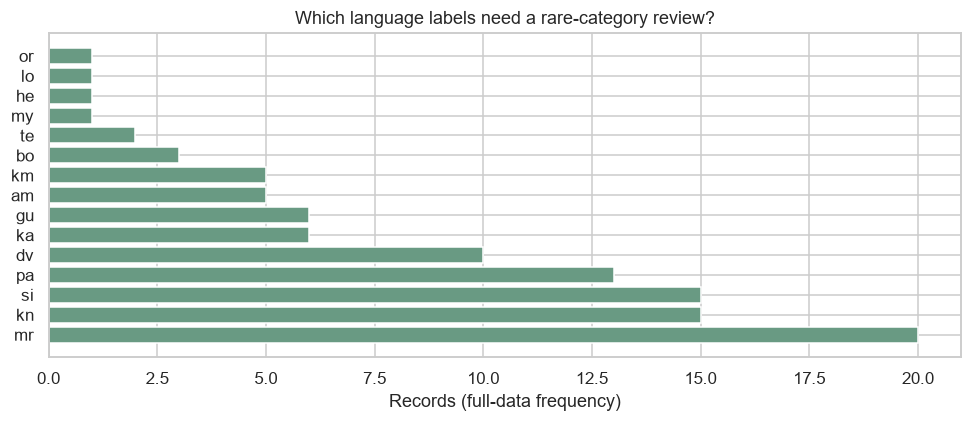

In [22]:
import json

# Review threshold only: rare categories are not automatically errors.
RARE_CATEGORY_MAX_COUNT = 10
category_tables, normalization_rows = [], []
for name in ["ioCountry", "post_language", "application_name"]:
    frequencies = df.loc[df[name].notna(), name].value_counts()
    table = frequencies.rename_axis("stored_value").reset_index(name="rows")
    table.insert(0, "column", name)
    table["percentage_all_rows"] = 100 * table["rows"] / N_ROWS
    table["rare_review_candidate"] = table["rows"].le(RARE_CATEGORY_MAX_COUNT)
    category_tables.append(table)
    normalized = table["stored_value"].str.strip().str.casefold()
    collision = normalized.duplicated(keep=False)
    for canonical, group in table.loc[collision].groupby(normalized[collision], sort=True):
        normalization_rows.append({
            "column": name, "comparison_form": canonical,
            "stored_variants": json.dumps(group["stored_value"].tolist(), ensure_ascii=False),
            "rows": int(group["rows"].sum()),
        })
    print(f"{name}: {len(table):,} categories; {int(table['rare_review_candidate'].sum()):,} rare candidates")
    display(pd.concat([table.head(5), table.tail(5)]).drop_duplicates())

category_frequencies = pd.concat(category_tables, ignore_index=True)
normalization_candidates = pd.DataFrame(
    normalization_rows, columns=["column", "comparison_form", "stored_variants", "rows"]
)
display(normalization_candidates)
language_tail = category_frequencies.loc[category_frequencies["column"].eq("post_language")].tail(15)
if len(language_tail):
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(language_tail["stored_value"], language_tail["rows"], color="#699a83")
    ax.set(xlabel="Records (full-data frequency)", title="Which language labels need a rare-category review?")
    fig.tight_layout()
    save_fig("rare_language_labels")
    plt.show()


**Findings**

Across all **8,714,356 posts**, using a rare-category threshold of **10 posts or fewer**:

- `ioCountry` has **5 categories**.
- `post_language` has **70 observed labels**. **11 labels** occur in 10 or fewer posts, covering **41 posts** in total: `dv` (10), `ka` (6), `gu` (6), `am` (5), `km` (5), `bo` (3), `te` (2), and `my`, `he`, `lo`, `or` (1 each).
- `application_name` has **3,728 stored categories**. **1,346 categories** are rare candidates, covering **4,391 posts**. These values are hashed application identifiers, so their meaning cannot be inferred from their labels alone.
- **No distinct stored labels collapse to the same case/whitespace comparison form** in these three columns. The normalization-candidate table is therefore empty. This check does not detect alternative language codes such as `in`/`id` and `iw`/`he`, which were examined separately above.



#### Hashtag representation: case and leading #

We saw that the same hashtag can be written with or without `#` and with different upper and lower case (`#Spa`, `spa`, `SPA`). We count all hashtag uses, how many have `#`, and how many different hashtags there are before and after lowercasing and removing `#`.

In [ ]:
with_hash = total = 0
distinct = set()
for chunk in iter_chunks(["hashtags"]):
    items = chunk["hashtags"].str.findall(r"'([^']*)'").explode().dropna()
    total += len(items)
    with_hash += items.str.startswith("#").sum()
    distinct.update(items.unique())

lowercase = {h.lower() for h in distinct}
cleaned = {h.lstrip("#").lower() for h in distinct}
print(f"hashtag uses: {total:,}, saved with #: {with_hash:,} ({100 * with_hash / total:.3f}%)")
print(f"different hashtags as written:          {len(distinct):,}")
print(f"after lowercasing:                      {len(lowercase):,}")
print(f"after lowercasing and removing #:       {len(cleaned):,}")
del distinct, lowercase, cleaned

hashtag uses: 9,354,974, saved with #: 317 (0.003%)
different hashtags as written:          637,935
after lowercasing:                      555,175
after lowercasing and removing #:       555,106


#### Repost and reply target availability patterns

The joint frequency tables display target-ID presence and absence across all records. **True** denotes a null target ID; **False** denotes a stored target ID. Repost patterns retain the raw `is_repost` labels. Both tables include zero-frequency combinations. The absence of both reply IDs may indicate structural inapplicability but does not independently establish non-reply status. Stored values are unchanged.


In [ ]:
# True denotes a null target ID; False denotes a stored target ID.
repost_patterns = pd.crosstab(
    [df["is_repost"], df["reposted_postid"].isna()],
    df["reposted_accountid"].isna(),
    rownames=["raw_is_repost", "post_target_missing"],
    colnames=["account_target_missing"],
    dropna=False,
)
# Include zero-frequency combinations so incomplete pairs remain visible.
repost_index = pd.MultiIndex.from_product(
    [df["is_repost"].unique(), [False, True]],
    names=["raw_is_repost", "post_target_missing"],
)
repost_patterns = repost_patterns.reindex(
    index=repost_index, columns=[False, True], fill_value=0
)
display(repost_patterns)

reply_patterns = pd.crosstab(
    df["in_reply_to_postid"].isna(), df["in_reply_to_accountid"].isna(),
    rownames=["reply_post_missing"], colnames=["reply_account_missing"],
    dropna=False,
).reindex(index=[False, True], columns=[False, True], fill_value=0)
display(reply_patterns)


account_target_missing               False    True 
raw_is_repost post_target_missing                  
False         False                      0        0
              True                       0  5109181
True          False                3605175        0
              True                       0        0

reply_account_missing,False,True
reply_post_missing,,
False,811619,74623
True,63468,7764646


**Findings**

- All **3,605,175 reposts** have both repost target IDs; all **5,109,181 non-reposts** have neither. No partial repost-target pairs or flag/target-presence contradictions were observed.
- Reply targets are both present in **811,619 records** and both absent in **7,764,646 records**. Another **138,091 records** have incomplete pairs: **63,468** lack only the post target and **74,623** lack only the account target.
- Incomplete reply metadata requires source-convention review and should not automatically be classified as erroneous. The tables assess availability, not target-ID correctness.


#### Target account consistency with referenced post authors

when the replied or reposted post is in our data, we know its author, so we can check if `in_reply_to_accountid` and `reposted_accountid` point to the same account.

In [ ]:
links = load(["in_reply_to_postid", "in_reply_to_accountid", "reposted_postid", "reposted_accountid"])
author = posts.drop_duplicates("postid").set_index("postid")["accountid"]
label = posts["is_control"].map(LABELS)

rows = []
for kind, post_col, account_col in [("reply", "in_reply_to_postid", "in_reply_to_accountid"),
                                    ("repost", "reposted_postid", "reposted_accountid")]:
    both_ids = links[post_col].notna() & links[account_col].notna()
    known = links[both_ids & links[post_col].isin(author.index)]
    match = known[account_col].values == author.loc[known[post_col]].values
    known_label = label.loc[known.index].values
    for cls in ["IO", "control"]:
        rows.append({
            "type": kind,
            "class": cls,
            "with both ids": (both_ids & (label == cls)).sum(),
            "original in our data": (known_label == cls).sum(),
            "account = real author": match[known_label == cls].sum(),
            "% agree": 100 * match[known_label == cls].mean(),
        })
del links, author, label
pd.DataFrame(rows).set_index(["type", "class"]).round(1)

with both ids  original in our data  account = real author  \
type   class                                                                 
reply  IO              589769                 11406                   7940   
       control         221748                 11912                  11911   
repost IO             2242703                141910                 108941   
       control        1362005                 16313                  12126   

                % agree  
type   class             
reply  IO        69.600  
       control  100.000  
repost IO        76.800  
       control   74.300

#### Collection artefacts

we included collection artefacts under inconsistencies because we saw that IO and control were collected differently, and that creates differences between the two classes that are not behaviour. We document them so that we don't build indicators that would separate the classes only because of how the data was collected.

In [ ]:
t = load(["post_time", "hashtags"])
t["is_control"] = posts["is_control"].map(LABELS)
t["accountid"] = posts["accountid"]
post_dt = pd.to_datetime(t["post_time"])
t["seconds_zero"] = post_dt.dt.second == 0
t["at_23"] = post_dt.dt.hour == 23
t["day"] = post_dt.dt.date
t["has_hashtag"] = t["hashtags"] != "[]"

artefacts = t.groupby("is_control")[["seconds_zero", "at_23", "has_hashtag"]].mean() * 100
artefacts["% users active on 1 day"] = t.groupby(["is_control", "accountid"])["day"].nunique().eq(1).groupby("is_control").mean() * 100
del t, post_dt
artefacts.round(1).rename(columns={"seconds_zero": "% posts with seconds = 00", "at_23": "% posts at 23:00", "has_hashtag": "% posts with hashtags"})

,% posts with seconds = 00,% posts at 23:00,% posts with hashtags,% users active on 1 day
is_control,,,,
IO,100.000,2.700,35.500,5.900
control,1.600,26.600,60.700,94.100


IO timestamps are rounded to the minute, and most control users have posts on one day only, so the control data looks like one day snapshots, many taken at 23:00. We have to keep this in mind for the time based indicators and for hashtags a difference there can come from the collection and not from the users.

### Duplicated records

postid should be unique, so a repeated postid is a duplicated record.

In [ ]:
dup = posts[posts["postid"].duplicated(keep=False)]

print(f"rows with a repeated postid: {len(dup):,} ({dup['postid'].nunique():,} distinct posts)")
print(f"extra copies to remove:      {posts['postid'].duplicated().sum():,}")
print("\ncopies per post:", dup["postid"].value_counts().value_counts().to_dict())
print("label of the duplicated rows:", dup["is_control"].value_counts().to_dict())
print("same post in different campaigns:", (dup.groupby("postid")["ioCountry"].nunique() > 1).sum())
conflict = dup[dup["is_control"] != "is_control?"].groupby("postid")["is_control"].nunique()
print(f"duplicated posts with different labels: {(conflict > 1).sum()}")

rows with a repeated postid: 45,614 (22,705 distinct posts)
extra copies to remove:      22,909

copies per post: {2: 22522, 3: 162, 4: 21}
label of the duplicated rows: {'True': 43726, 'False': 1886, 'is_control?': 2}
same post in different campaigns: 20838
duplicated posts with different labels: 2


We are thinking if the copies are really identitcal or different? We can take all columns of the duplicated rows and compare them to see if they are really same or different.

In [ ]:
dup_ids = set(dup["postid"])
dup_rows = pd.concat(chunk[chunk["postid"].isin(dup_ids)] for chunk in iter_chunks(None))
other_cols = dup_rows.columns.drop("postid")
differs = dup_rows.groupby("postid")[list(other_cols)].nunique(dropna=False).gt(1).sum()
print("posts whose copies differ in each column:")
print(differs[differs > 0].to_dict())
del dup_rows

posts whose copies differ in each column:
{'ioCountry': 20838, 'post_text': 148, 'application_name': 39, 'post_language': 30, 'in_reply_to_postid': 2, 'in_reply_to_accountid': 4, 'post_time': 1, 'accountid': 234, 'account_profile_description': 409, 'follower_count': 11228, 'following_count': 9929, 'account_creation_date': 194, 'is_repost': 12, 'reposted_accountid': 48, 'reposted_postid': 67, 'hashtags': 75, 'urls': 117, 'account_mentions': 56, 'is_control': 4}


then we check if some rows are identical in all 20 columns. Loading all columns together is heavy, so we hash every row chunk by chunk and look for repeated hashes.

In [47]:
row_hash = pd.concat(pd.util.hash_pandas_object(chunk, index=False) for chunk in iter_chunks(None))
print(f"rows:           {len(row_hash):,}")
print(f"identical rows: {row_hash.duplicated(keep=False).sum():,}")
print(f"extra copies:   {row_hash.duplicated().sum():,}")

rows:           8,714,356
identical rows: 3,158
extra copies:   1,579


### Outliers

we look at outliers per account, because the account values are repeated on every post and active accounts would count many times. For followers and following we take the median of the account's valid values (the wrong ones from above are removed). We use the two rules from the slides interquartile range IQR, where a value is an outlier if it is below Q_1 - 1.5.IQR or above Q_3 + 1.5.IQR, and z-score, where a value is an outlier if $|z| > 3.29$.

In [ ]:
raw = load(["accountid", "follower_count", "following_count"])
raw["is_control"] = posts["is_control"]
for col in ["follower_count", "following_count"]:
    n = pd.to_numeric(raw[col], errors="coerce")
    raw[col] = n.where((n >= 0) & (n < 1e9))

users = raw.groupby("accountid").agg(
    posts=("accountid", "size"),
    followers=("follower_count", "median"),
    following=("following_count", "median"),
    label=("is_control", lambda s: s[s != "is_control?"].mode().iloc[0]),
)
users["label"] = users["label"].map(LABELS)
del raw


def outlier_counts(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    z = (s - s.mean()) / s.std()
    return pd.Series({
        "Q1": q1, "Q3": q3, "upper IQR bound": q3 + 1.5 * iqr,
        "IQR outliers": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum(),
        "z-score outliers": (z.abs() > 3.29).sum(),
        "max": s.max(),
    })


users[["posts", "followers", "following"]].apply(outlier_counts).T.astype("int64")

,Q1,Q3,upper IQR bound,IQR outliers,z-score outliers,max
posts,6,84,201,4829,201,265498
followers,95,1398,3353,11813,189,19912528
following,117,1215,2862,9674,352,2301841


The three variables are very skewed, so the IQR rule marks many accounts as outliers, and the z-score is pulled by the extreme values themselves. On a log scale the picture is clearer:

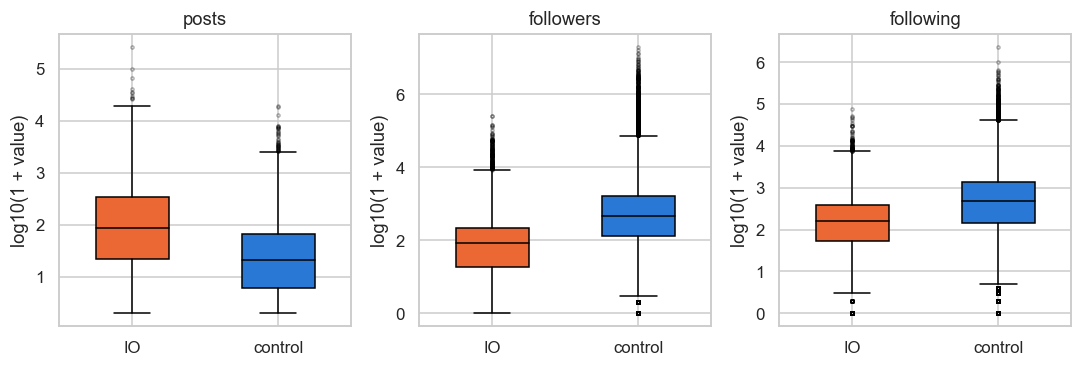

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, col in zip(axes, ["posts", "followers", "following"]):
    data = [np.log10(1 + users.loc[users["label"] == k, col].dropna()) for k in ["IO", "control"]]
    box = ax.boxplot(data, labels=["IO", "control"], patch_artist=True, widths=0.5,
                     flierprops={"markersize": 2, "alpha": 0.3}, medianprops={"color": "black"})
    for patch, k in zip(box["boxes"], ["IO", "control"]):
        patch.set_facecolor(CLASS_COLORS[k])
    ax.set_title(col)
    ax.set_ylabel("log10(1 + value)")
plt.tight_layout()
save_fig("outliers_boxplots")
plt.show()

The extreme values (for example an account with more than 265k posts, or accounts with millions of followers) are rare but real, so we don't remove them. We use a log transform for these variables, which brings them to a comparable scale.

### Summary

| Problem | Where | we can fix in cleaning |
| --- | --- | --- |
| text instead of numbers, negative and huge values | `follower_count`, `following_count` | median of the account's valid values |
| `is_control?` | `is_control` | label from the account's other posts |
| real missing values | `post_language`, `follower_count`, `following_count`, `post_text` | keep `post_language` missing as its own value, counts as above |
| hidden missing value `und` | `post_language` | decide if it counts as a language in the language indicators |
| duplicated posts (22,909 extra copies) | `postid` | keep one copy, but first check the 234 ids with different authors |
| identical rows, same value in all 20 columns (3,158 rows, 1,579 extra copies) | all columns | drop the extra copies, they are part of the 22,909 duplicated posts |
| account with both labels, posts with different labels | `is_control` | use the label of most of its posts (IO) |
| control accounts in more than one campaign | `ioCountry` | keep the campaign with most posts |
| two codes for one language | `post_language` | `in` → `id`, `iw` → `he` |
| same hashtag in different case or with `#` (637,935 → 555,106 different hashtags) | `hashtags` | lowercase and remove `#` |
| text length inflated by the codes and reply mentions | `post_text` | remove them before measuring the length |
| unreliable reply and repost ids | reply and repost columns | use counts, not exact links |
| collection artefacts (rounded seconds, one-day snapshots, posts at 23:00, more hashtags in control) | `post_time`, `hashtags` | keep, but don't use seconds or hour, and be careful with time span and hashtag indicators |
| skewed variables with extreme values | posts, followers, following | keep, log transform |
| Whitespace-only text: 2 posts contain only whitespace, including Unicode spaces, but are not null | `post_text`; **Missing values**, hidden-marker audit | Yes: strip whitespace and convert empty results to missing before calculating text features. Keep these separate from the 3 existing null texts. |
| Possible placeholder text is stored as ordinary text: `Null` (1), `?` (12), and `-` (5) in posts; `-` (114), `?` (31), `Undefined` (10), and `Unknown` (27) in bios | `post_text`, `account_profile_description`; **Missing values**, hidden-marker audit | Review first: these may be intentional text. Convert only confirmed placeholders to missing; do not apply a blanket replacement across free-text fields. |
| Missing profile descriptions: 1,669,919 post records have a null bio; this is not necessarily an error or the number of affected accounts | `account_profile_description`; **Missing values** | Partly: retain a missing-bio flag and handle missing text explicitly. Do not invent a bio or assume the account never had one. |
| Incomplete reply-target pairs: 138,091 posts; 63,468 lack only the post ID and 74,623 lack only the account ID | `in_reply_to_postid`, `in_reply_to_accountid`; **Repost and reply target availability patterns** | Partly: check source conventions, flag incomplete pairs, and preserve the known ID. Recover a missing author only from a referenced post with an unambiguous author; otherwise leave it unknown. Missing both IDs does not by itself prove a non-reply. |
| Very rare language labels: 11 labels occur in 10 or fewer posts each, covering 41 posts; rarity alone does not establish an error | `post_language`; **Category frequencies and normalization candidates** | Review first: apply the already planned language-code mapping before reassessing frequencies. Keep valid rare languages; optionally group them as `other` for indicators without overwriting the stored labels. |
| Many rare application identifiers: 1,346 of 3,728 categories occur in 10 or fewer posts each, covering 4,391 posts; identifiers are hashed | `application_name`; **Category frequencies and normalization candidates** | Partly: preserve valid identifiers and optionally group infrequent apps for indicators. Rarity is not a reason to delete records, and cleaning cannot recover app names from the hashes. |
| Publication timestamps have no explicit timezone in all 8,714,356 records, so UTC-based comparisons rely on an assumption | `post_time`; **Supplementary date validity and timezone checks** | Requires source documentation: confirm the source timezone before localizing or converting timestamps. Otherwise document the UTC assumption and avoid claims about local posting hours. Compare account creation dates at day granularity. |

Counts for the appended findings come from the saved full-dataset audit outputs (8,714,356 records); review candidates are not automatically errors. The incomplete reply-pair row adds detail to the existing interaction-ID problem, so their affected records overlap.

The documented source observation window is also not configured, so that check remains unperformed; this is an audit limitation, not a detected out-of-window error. The added checks found no malformed or elided collections, noncanonical Boolean spellings, case/whitespace category collisions, or additional date-validity errors, so these are not added as problems.


## Distributions

now we will do the distribution of the variables at post level, always comparing IO and control posts. The account level comes later, with the user profiles. We have not cleaned the data yet, so for followers and following we only use the valid values (no text, no negative values, nothing above 1 billion).

### Descriptive statistics

after followers and following, we compute some numbers for each post like the text length (without the 42 character codes and the mentions at the start of replies), and the number of hashtags, links and mentions. In reposts the first mention is always the reposted author, so we don't count it.

In [ ]:
LIST_COLS = ["hashtags", "urls", "account_mentions"]

parts = []
for chunk in iter_chunks(["follower_count", "following_count", "post_text", "is_repost"] + LIST_COLS):
    part = pd.DataFrame()
    for col in ["follower_count", "following_count"]:
        n = pd.to_numeric(chunk[col], errors="coerce")
        part[col] = n.where((n >= 0) & (n < 1e9))
    text = chunk["post_text"].str.replace(HEX_ID, "", regex=True).str.replace(r"^(?:@\s*)+", "", regex=True)
    part["text_length"] = text.str.len()
    for col in LIST_COLS:
        part[f"n_{col}"] = chunk[col].str.count(r"'[^']*'")
    part["n_account_mentions"] -= (chunk["is_repost"] == "True").astype(int)
    parts.append(part)

post_num = pd.concat(parts, ignore_index=True)
post_num["label"] = pd.Categorical(load(["is_control"])["is_control"].map(LABELS))
post_num = post_num.rename(columns={"n_hashtags": "hashtags", "n_urls": "links", "n_account_mentions": "mentions"})
del parts, part, chunk, text
post_num.head()

,follower_count,following_count,text_length,hashtags,links,mentions,label
0,"1,528.000","2,619.000",58.000,0,0,0,IO
1,"1,528.000","2,619.000",133.000,0,0,0,IO
2,35.000,215.000,92.000,0,0,1,IO
3,35.000,215.000,139.000,0,0,0,IO
4,35.000,215.000,139.000,0,0,0,IO


In [ ]:
NUM_VARS = ["follower_count", "following_count", "text_length", "hashtags", "links", "mentions"]


def describe(s):
    q1, median, q3 = s.quantile([0.25, 0.5, 0.75])
    return pd.Series({
        "mean": s.mean(), "std": s.std(), "min": s.min(), "Q1": q1, "median": median,
        "Q3": q3, "IQR": q3 - q1, "max": s.max(), "mode": s.mode().iloc[0],
    })


stats = {}
for var in NUM_VARS:
    for group in ["all", "IO", "control"]:
        s = post_num[var] if group == "all" else post_num.loc[post_num["label"] == group, var]
        stats[(var, group)] = describe(s.dropna())
stats = pd.DataFrame(stats).T
stats.round(1)

mean         std   min      Q1  median  \
follower_count  all     13,231.100 203,128.900 0.000 182.000 714.000   
                IO       4,906.200  15,902.000 0.000 149.000 588.000   
                control 25,732.600 320,294.600 0.000 254.000 969.000   
following_count all      2,427.800  12,004.900 0.000 166.000 499.000   
                IO       1,795.800   3,971.600 0.000 193.000 469.000   
                control  3,376.500  18,309.400 0.000  92.000 555.000   
text_length     all         87.400      46.800 0.000  56.000  84.000   
                IO          84.000      42.200 0.000  56.000  81.000   
                control     92.500      52.700 0.000  57.000  89.000   
hashtags        all          1.100       1.900 0.000   0.000   0.000   
                IO           0.700       1.400 0.000   0.000   0.000   
                control      1.600       2.300 0.000   0.000   1.000   
links           all          0.700       0.600 0.000   0.000   1.000   
                IO           0.700       0.700 0.000   0.000   1.000   
                control      0.700       0.600 0.000   0.000   1.000   
mentions        all          0.400       1.300 0.000   0.000   0.000   
                IO           0.300       0.900 0.000   0.000   0.000   
                control      0.500       1.800 0.000   0.000   0.000   

                               Q3       IQR            max      mode  
follower_count  all     3,042.000 2,860.000 19,912,528.000 8,012.000  
                IO      2,748.000 2,599.000    259,966.000 8,012.000  
                control 3,408.000 3,154.000 19,912,528.000     0.000  
following_count all     1,686.000 1,520.000  2,301,841.000     0.000  
                IO      1,559.000 1,366.000     74,664.000 1,450.000  
                control 1,963.000 1,871.000  2,301,841.000     0.000  
text_length     all       117.000    61.000      1,030.000   120.000  
                IO        114.000    58.000        318.000   120.000  
                control   120.000    63.000      1,030.000   124.000  
hashtags        all         1.000     1.000         40.000     0.000  
                IO          1.000     1.000         40.000     0.000  
                control     2.000     2.000         36.000     0.000  
links           all         1.000     1.000          9.000     1.000  
                IO          1.000     1.000          7.000     1.000  
                control     1.000     1.000          9.000     1.000  
mentions        all         0.000     0.000         50.000     0.000  
                IO          0.000     0.000         50.000     0.000  
                control     1.000     1.000         50.000     0.000

This table is at post level, so active accounts count many times. That is why the mode of followers for IO is 8,012, it is one account with a lot of posts. Followers and following are very skewed (the mean is far above the median), control posts come from accounts with more followers, and control posts have more hashtags (median 1 against 0). Text length, links and mentions are similar in the two classes.

### Numeric distributions

now we want to see the histograms of followers and following on the log scale. The number of bins comes from Sturges' rule, $k = \lceil \log_2 n + 1 \rceil$. The y-axis is the percentage of posts of each class, so IO and control can be compared even if they don't have the same number of posts.

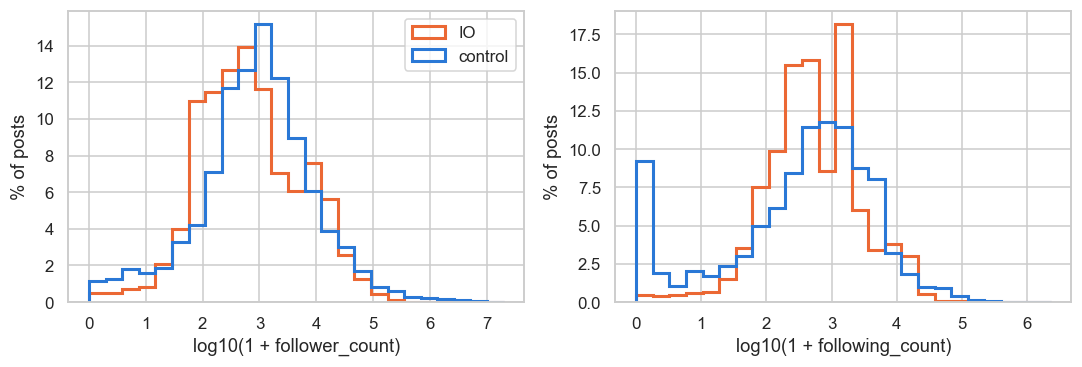

Sturges bins: 25


In [ ]:
def class_hist(ax, values, bins):
    for cls in ["IO", "control"]:
        v = values[post_num["label"] == cls].dropna()
        ax.hist(v, bins=bins, histtype="step", linewidth=2, color=CLASS_COLORS[cls],
                label=cls, weights=np.full(len(v), 100 / len(v)))
    ax.set_ylabel("% of posts")


fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["follower_count", "following_count"]):
    values = np.log10(1 + post_num[col])
    k = int(np.ceil(np.log2(values.notna().sum()) + 1))
    class_hist(ax, values, np.linspace(0, values.max(), k + 1))
    ax.set_xlabel(f"log10(1 + {col})")
axes[0].legend()
plt.tight_layout()
save_fig("dist_followers_following")
plt.show()
print(f"Sturges bins: {k}")

We saw that very long texts are rare, so the plot stops at the 99.9th percentile.

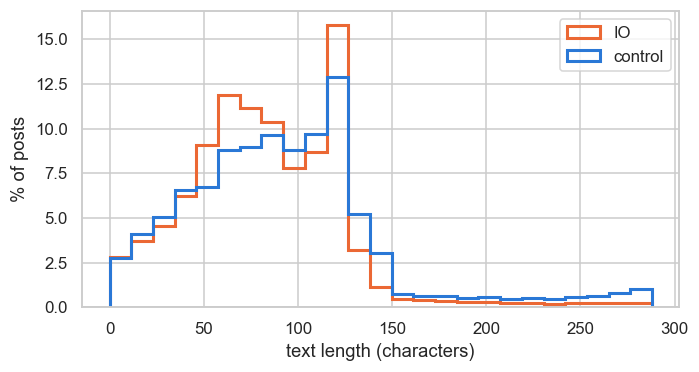

In [ ]:
upper = post_num["text_length"].quantile(0.999)
fig, ax = plt.subplots(figsize=(7, 3.5))
class_hist(ax, post_num["text_length"].clip(upper=upper), np.linspace(0, upper, k + 1))
ax.set_xlabel("text length (characters)")
ax.legend()
save_fig("dist_text_length")
plt.show()

Most posts are short. IO posts almost never go above 140 characters, while control has a small tail up to 280.

now hashtags, links and mentions per post. These are small whole numbers, so we use bar charts, with 5 or more grouped together.

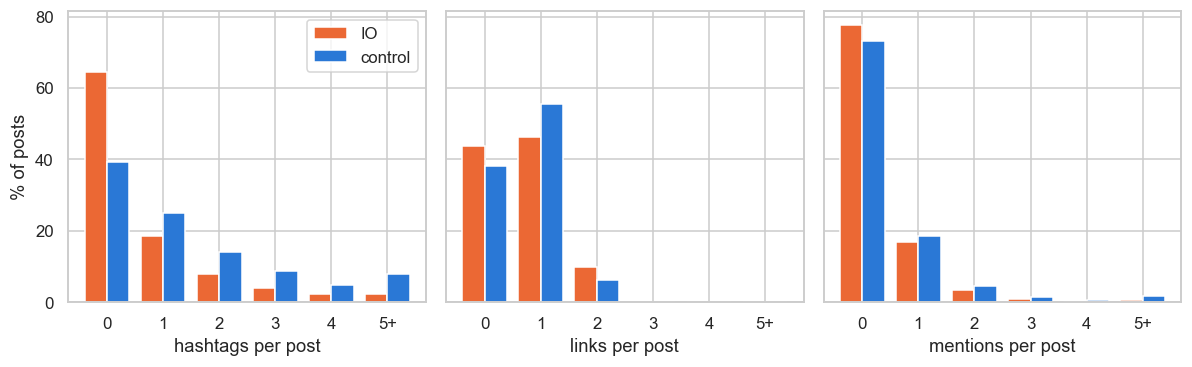

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharey=True)
for ax, col in zip(axes, ["hashtags", "links", "mentions"]):
    share = pd.crosstab(post_num[col].clip(upper=5), post_num["label"], normalize="columns") * 100
    x = np.arange(len(share))
    for i, cls in enumerate(["IO", "control"]):
        ax.bar(x + (i - 0.5) * 0.4, share[cls], width=0.4, color=CLASS_COLORS[cls], label=cls, edgecolor="white")
    ax.set_xticks(x, [str(v) for v in share.index[:-1]] + ["5+"])
    ax.set_xlabel(f"{col} per post")
axes[0].set_ylabel("% of posts")
axes[0].legend()
plt.tight_layout()
save_fig("dist_hashtags_links_mentions")
plt.show()

we can see that 64% of IO posts have no hashtag, against 39% of control posts, but control users were collected by searching hashtags, so this difference is partly a collection artefact. Links and mentions are similar: about half of the posts have one link and most posts have no mention.

### Categorical distributions

number of posts for each campaign.

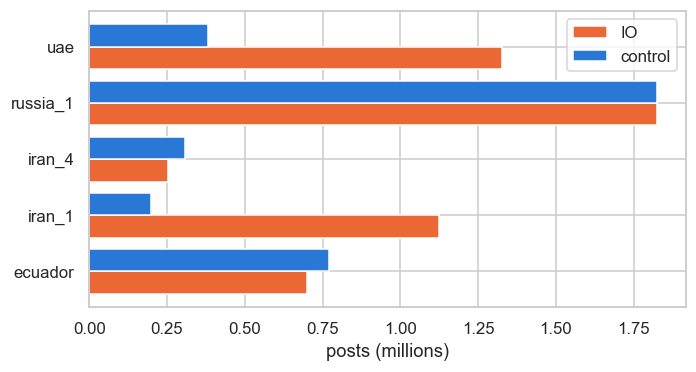

label,IO,control
ioCountry,,
ecuador,700274,770338
iran_1,1122977,199873
iran_4,254797,306822
russia_1,1826432,1823841
uae,1325597,382293


In [ ]:
campaign = load(["ioCountry"])["ioCountry"]
posts_per_campaign = pd.crosstab(campaign, post_num["label"])[["IO", "control"]]

fig, ax = plt.subplots(figsize=(7, 3.5))
y = np.arange(len(posts_per_campaign))
for i, cls in enumerate(["IO", "control"]):
    ax.barh(y + (i - 0.5) * 0.4, posts_per_campaign[cls] / 1e6, height=0.4, color=CLASS_COLORS[cls], label=cls)
ax.set_yticks(y, posts_per_campaign.index)
ax.set_xlabel("posts (millions)")
ax.legend()
save_fig("dist_campaigns")
plt.show()
posts_per_campaign

russia_1 is the biggest campaign. iran_1 and uae have many more IO than control posts, while in ecuador and iran_4 the control posts are a bit more.

every post is an original post, a reply or a repost.

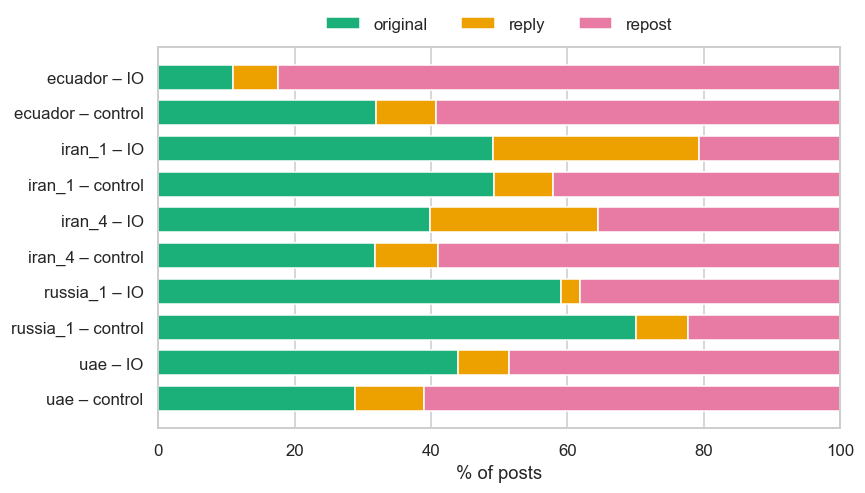

col_0              original  reply  repost
ioCountry label                           
ecuador   IO         10.900  6.600  82.500
          control    32.000  8.700  59.300
iran_1    IO         49.100 30.200  20.700
          control    49.200  8.700  42.100
iran_4    IO         39.900 24.600  35.500
          control    31.800  9.100  59.000
russia_1  IO         59.100  2.700  38.200
          control    70.100  7.600  22.300
uae       IO         43.900  7.500  48.600
          control    28.800 10.100  61.100

In [ ]:
TYPE_COLORS = {"original": "#1baf7a", "reply": "#eda100", "repost": "#e87ba4"}
kind = load(["is_repost", "in_reply_to_postid"])
post_type = pd.Series(np.select([kind["is_repost"] == "True", kind["in_reply_to_postid"].notna()],
                                ["repost", "reply"], "original"))
del kind

types = pd.crosstab([campaign, post_num["label"]], post_type, normalize="index")[list(TYPE_COLORS)] * 100
types = types.loc[types.index.get_level_values(1).isin(["IO", "control"])]

fig, ax = plt.subplots(figsize=(8, 4.5))
left = np.zeros(len(types))
labels = [f"{c} – {cls}" for c, cls in types.index]
for t, color in TYPE_COLORS.items():
    ax.barh(labels, types[t], left=left, color=color, label=t, edgecolor="white", height=0.7)
    left += types[t].values
ax.invert_yaxis()
ax.set_xlabel("% of posts")
ax.set_xlim(0, 100)
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
save_fig("dist_post_types")
plt.show()
types.round(1)

The mix of post types changes a lot between campaigns. ecuador IO is mostly reposts (83%), iran_1 and iran_4 IO reply much more than control (30% and 25% against about 9%), and russia_1 IO writes mostly original posts. So the campaigns used different strategies, and the type of post will be useful for the user profiles.

The 10 most used languages, the rest grouped as other.

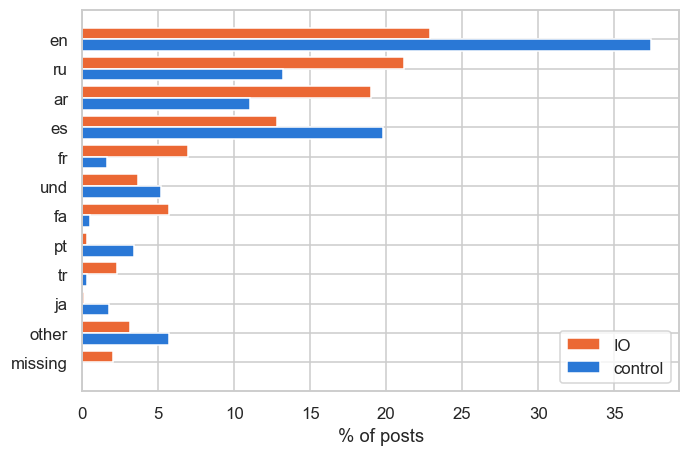

In [ ]:
lang = load(["post_language"])["post_language"].fillna("missing")
top = lang[lang != "missing"].value_counts().index[:10]
lang = lang.where(lang.isin(top) | (lang == "missing"), "other")
lang_share = pd.crosstab(lang, post_num["label"], normalize="columns")[["IO", "control"]] * 100
lang_share = lang_share.loc[list(top) + ["other", "missing"]]
del lang

fig, ax = plt.subplots(figsize=(7, 4.5))
y = np.arange(len(lang_share))
for i, cls in enumerate(["IO", "control"]):
    ax.barh(y + (i - 0.5) * 0.4, lang_share[cls], height=0.4, color=CLASS_COLORS[cls], label=cls)
ax.set_yticks(y, lang_share.index)
ax.invert_yaxis()
ax.set_xlabel("% of posts")
ax.legend()
save_fig("dist_languages")
plt.show()

IO posts are more in Russian, Arabic, French and Persian, control posts more in English, Spanish, Portuguese and Japanese. So the languages depend on the campaign targets. The missing languages are only in IO posts, as we saw in the data quality part.

The app names are hashed, so we look at how concentrated their use is like how many apps each class uses and what share of the posts the most used apps cover.

In [ ]:
app = load(["application_name"])["application_name"]
rows = {}
for cls in ["IO", "control"]:
    counts = app[post_num["label"] == cls].value_counts()
    rows[cls] = {
        "apps used": len(counts),
        "% posts top 1 app": 100 * counts.iloc[0] / counts.sum(),
        "% posts top 10 apps": 100 * counts.iloc[:10].sum() / counts.sum(),
        "% posts top 100 apps": 100 * counts.iloc[:100].sum() / counts.sum(),
    }
del app
pd.DataFrame(rows).T.round(1)

,apps used,% posts top 1 app,% posts top 10 apps,% posts top 100 apps
IO,428.000,33.000,82.000,99.600
control,"3,468.000",19.900,73.100,91.400


we can see that IO posts use only 428 apps and the top 100 cover 99.6% of their posts, while control uses 3,468 apps. Control has many more accounts, so it naturally has more apps, but IO is clearly more concentrated: one app alone covers a third of the IO posts.

### Time

Posts per month.

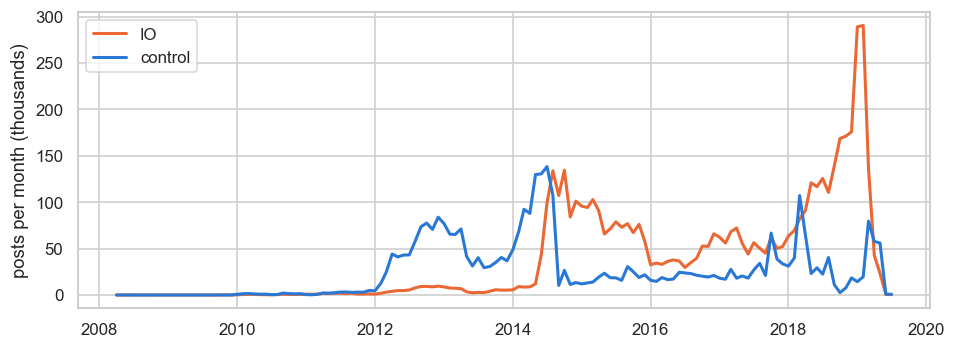

In [ ]:
month = pd.to_datetime(load(["post_time"])["post_time"].str[:7])
per_month = pd.crosstab(month, post_num["label"])[["IO", "control"]]

fig, ax = plt.subplots(figsize=(10, 3.5))
for cls in ["IO", "control"]:
    ax.plot(per_month.index, per_month[cls] / 1e3, color=CLASS_COLORS[cls], linewidth=2, label=cls)
ax.set_ylabel("posts per month (thousands)")
ax.legend()
save_fig("dist_posts_per_month")
plt.show()

we can see that control posts are mostly in 2012–2014 and in 2018. IO activity starts in 2014 and has a big peak at the end of 2018 and beginning of 2019 (almost 300 thousand posts per month), then the data stops in mid 2019.

now we want to see how many accounts created per month. One row per account, with the label of its first post.

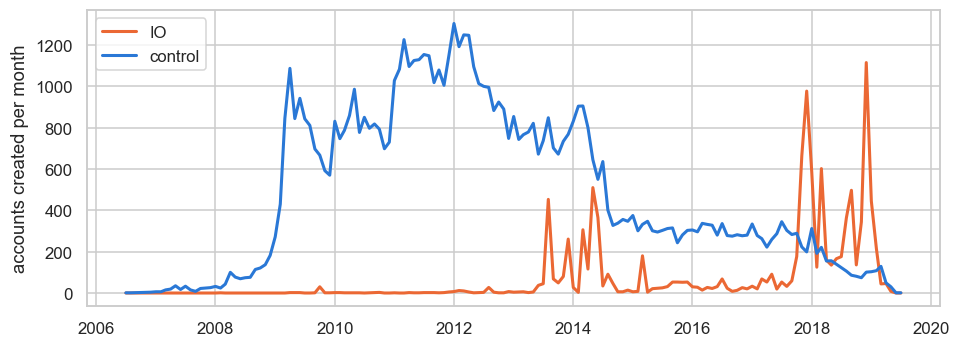

months with most IO accounts created:
account_creation_date
2018-12-01    1115
2017-12-01     977
2017-11-01     663
2018-03-01     602
2018-01-01     585
Name: IO, dtype: int64


In [ ]:
accounts = load(["accountid", "account_creation_date"])
accounts["label"] = post_num["label"]
accounts = accounts.dropna(subset=["label"]).drop_duplicates("accountid")
created = pd.crosstab(pd.to_datetime(accounts["account_creation_date"].str[:7]), accounts["label"])[["IO", "control"]]

fig, ax = plt.subplots(figsize=(10, 3.5))
for cls in ["IO", "control"]:
    ax.plot(created.index, created[cls], color=CLASS_COLORS[cls], linewidth=2, label=cls)
ax.set_ylabel("accounts created per month")
ax.legend()
save_fig("dist_accounts_created")
plt.show()
print("months with most IO accounts created:")
print(created["IO"].nlargest(5))
del accounts

control accounts were mostly created between 2009 and 2014, so they are older accounts. IO accounts were created in a few short peaks, with 977 in December 2017 and 1,115 in December 2018, which fits accounts created in batches for a campaign.

**Hour of the day.**

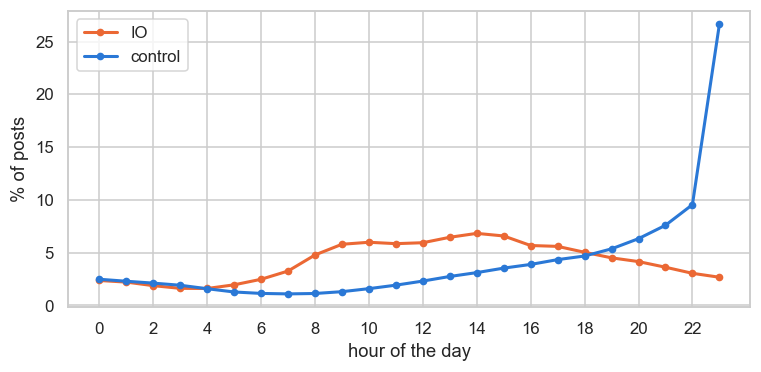

In [ ]:
hour = load(["post_time"])["post_time"].str[11:13].astype(int)
per_hour = pd.crosstab(hour, post_num["label"], normalize="columns")[["IO", "control"]] * 100

fig, ax = plt.subplots(figsize=(8, 3.5))
for cls in ["IO", "control"]:
    ax.plot(per_hour.index, per_hour[cls], color=CLASS_COLORS[cls], linewidth=2, marker="o", markersize=4, label=cls)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of the day")
ax.set_ylabel("% of posts")
ax.legend()
save_fig("dist_hour")
plt.show()
del hour, month

IO posts follow a working day pattern, mostly between 8:00 and 17:00 (the time zone is not known). The control peak at 23:00 is the collection artefact we saw before, not real behaviour, so we don't use the hour as an indicator.

## Correlations

now we want to see the relationships between pairs of variables at post level, and columns that repeat the same information. 

### Numeric variables

from the slide we saw that pearson measures a linear relationship. Spearman does the same on the ranks of the values, so it is not pulled by the extreme values of skewed variables. `is_reply` and `is_repost` are 1 if the post is a reply or a repost, 0 otherwise.

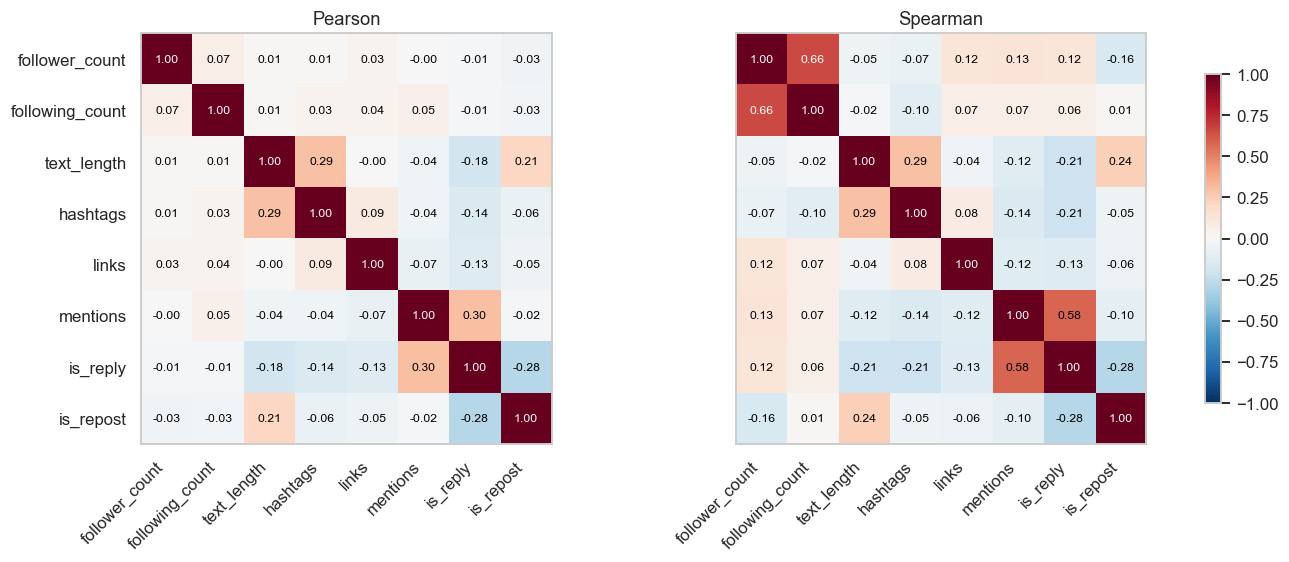

In [ ]:
num = post_num[NUM_VARS].assign(is_reply=(post_type == "reply").astype(int).values,
                                 is_repost=(post_type == "repost").astype(int).values)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = num.corr(method=method)
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr)), corr.columns if ax is axes[0] else [])
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
    ax.set_title(method.capitalize())
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8)
save_fig("corr_numeric")
plt.show()
del num

we can see that pearson is close to 0 for almost every pair. Spearman shows more: followers and following are clearly related (0.66), which Pearson misses (0.07) because of the extreme values. Replies mention more accounts (0.58), since a reply mentions the account it answers, and a post can't be a reply and a repost at the same time (-0.28). Longer texts have a few more hashtags (0.29). No pair is close to 1, so none of these numeric variables repeats another one.

### Followers and following

with 8.7 million points a scatter plot can be just a blob, so we draw a random sample of 20,000 posts per class.

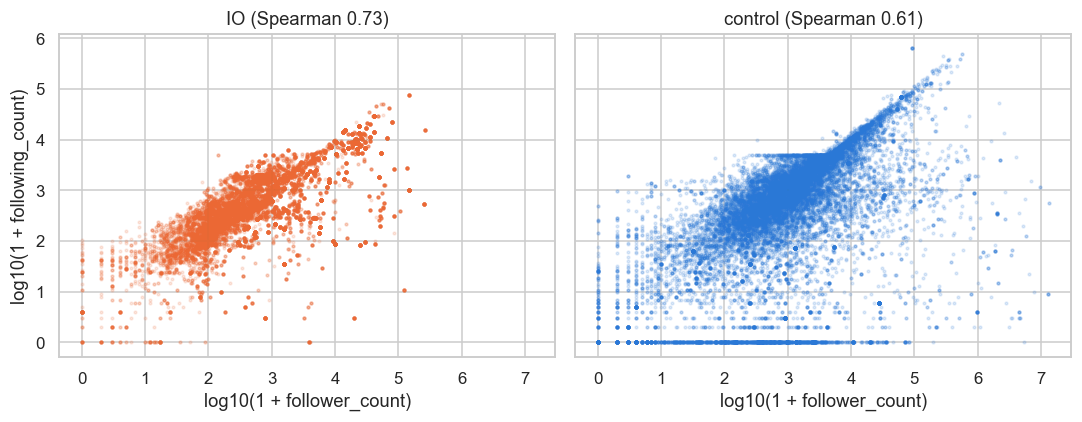

In [ ]:
sample = (post_num.dropna(subset=["follower_count", "following_count", "label"])
          .groupby("label", observed=True).sample(20_000, random_state=RANDOM_STATE))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, cls in zip(axes, ["IO", "control"]):
    s = sample[sample["label"] == cls]
    ax.scatter(np.log10(1 + s["follower_count"]), np.log10(1 + s["following_count"]),
               s=3, alpha=0.15, color=CLASS_COLORS[cls])
    rho = s["follower_count"].corr(s["following_count"], method="spearman")
    ax.set_title(f"{cls} (Spearman {rho:.2f})")
    ax.set_xlabel("log10(1 + follower_count)")
axes[0].set_ylabel("log10(1 + following_count)")
plt.tight_layout()
save_fig("corr_followers_following")
plt.show()
del sample

In both classes accounts that follow more people also have more followers (Spearman 0.73 for IO, 0.61 for control). Control has two lines: one at 0 (accounts that follow nobody) and one around 3.7, which is about 5,000 accounts followed.

### Campaign and language

Contingency table between two categorical variables the share of each language inside each campaign (each row sums to 100).

In [ ]:
lang = load(["post_language"])["post_language"].fillna("missing")
top = lang[lang != "missing"].value_counts().index[:8]
lang = lang.where(lang.isin(top) | (lang == "missing"), "other")
campaign_lang = pd.crosstab([campaign, post_num["label"]], lang, normalize="index")[list(top) + ["other", "missing"]] * 100
del lang
campaign_lang.round(1)

post_language         en     ru     ar     es     fr   und     fa    pt  \
ioCountry label                                                           
ecuador   IO       9.200  0.700  0.100 79.700  0.300 3.100  0.000 0.400   
          control 19.000  0.100  0.300 65.200  0.700 6.600  0.000 3.200   
iran_1    IO      24.700  3.600 13.700  5.800 28.800 3.800  8.200 0.100   
          control 59.300  0.900  4.900 18.400  2.600 4.900  0.400 1.100   
iran_4    IO      12.700  0.000 11.600  0.000  0.100 5.800 68.900 0.000   
          control 44.000  0.100 34.700  5.400  1.000 5.100  5.200 0.500   
russia_1  IO      32.600 57.000  0.400  0.100  0.100 2.400  0.000 0.000   
          control 44.100 25.100  2.200  6.900  2.200 4.600  0.000 4.700   
uae       IO      17.000  1.700 60.500  3.300  2.600 5.200  2.400 0.800   
          control 25.900  0.100 59.200  2.200  0.700 5.300  0.400 1.300   

post_language      other  missing  
ioCountry label                    
ecuador   IO       2.500    3.900  
          control  5.000    0.000  
iran_1    IO      10.700    0.500  
          control  7.500    0.000  
iran_4    IO       0.700    0.000  
          control  3.900    0.000  
russia_1  IO       3.600    3.600  
          control 10.300    0.000  
uae       IO       6.200    0.300  
          control  5.000    0.000

each campaign has a main language like Spanish for ecuador, Persian for iran_4 IO, Russian for russia_1 IO, Arabic for uae, and French and English for iran_1 IO. So the language is partly redundant with the campaign. IO posts are more concentrated on the target language, while control posts have more English. The missing languages are only in IO posts.

### Redundant information

some columns repeat information that is already in other columns. For each pair we count in how many posts the two agree.

In [ ]:
checks = {
    "is_repost = True  <=>  reposted_postid filled": 0,
    "reposted_postid filled  <=>  reposted_accountid filled": 0,
    "in_reply_to_postid filled  <=>  in_reply_to_accountid filled": 0,
    "repost: first mention = reposted_accountid": 0,
}
checked = dict.fromkeys(checks, 0)
cols = ["is_repost", "reposted_postid", "reposted_accountid", "in_reply_to_postid", "in_reply_to_accountid", "account_mentions"]
for chunk in iter_chunks(cols):
    repost = chunk["is_repost"] == "True"
    first_mention = chunk.loc[repost, "account_mentions"].str.extract(r"'([^']*)'")[0]
    agree = [
        repost == chunk["reposted_postid"].notna(),
        chunk["reposted_postid"].notna() == chunk["reposted_accountid"].notna(),
        chunk["in_reply_to_postid"].notna() == chunk["in_reply_to_accountid"].notna(),
        first_mention == chunk.loc[repost, "reposted_accountid"],
    ]
    for name, a in zip(checks, agree):
        checks[name] += a.sum()
        checked[name] += len(a)

redundancy = pd.DataFrame({"posts checked": checked, "agree": checks})
redundancy["% agree"] = (100 * redundancy["agree"] / redundancy["posts checked"]).round(2)
del chunk
redundancy

,posts checked,agree,% agree
is_repost = True <=> reposted_postid filled,8714356,8714356,100.000
reposted_postid filled <=> reposted_accountid filled,8714356,8714356,100.000
in_reply_to_postid filled <=> in_reply_to_accountid filled,8714356,8576265,98.420
repost: first mention = reposted_accountid,3605175,3605175,100.000


`is_repost` and the two repost columns always agree, and in every repost the first mention is the reposted author, so these columns carry the same information. The two reply columns agree in 98.4% of the posts. For the user profiles this means `is_repost` is enough to count reposts, `in_reply_to_postid` is enough to count replies, and when counting mentions we must skip the first mention of reposts because it is the author of the reposted post (reposted_accountid).